# Designed hierarchy initialisations: one section per run

Each run trains a bias-free ReLU MLP on depth-5 COB-ODT data (d = 100) from a hand-designed init:
30 **probes** in the first layer (rows 0-29; probe 2j should reach +u_j and probe 2j+1 should reach -u_j,
for the 15 internal nodes j = 0..14), 32 **cues** (rows 30-61) sitting on the signed level-4 normals
+-u_15..u_30 with a small off-span component, and optionally random rows after them. Second-layer units
wire each probe (weight -1) with linear cue pairs (+1 on a cue, -1 on its twin) chosen so that at t = 0
the population gradient pushes the probe toward its target and the pushes along ancestors cancel.
The third layer is 0/1, the output all ones (or balanced +-1), and every row of every layer is rescaled
to the Kaiming norm sqrt(2). Training: SGD, momentum 0.9, lr 0.02 annealed by cosine to 0.001 over
1000 epochs of 1000 steps, fixed batch order, design seed 0, training seed 1000, all four weight
matrices stored every 10 epochs. "Cues frozen" means the 32 cue rows never move.

Metrics used in the findings (end of training unless stated, alignment threshold |cos| > 0.95):
*nodes covered* = distinct ODT nodes that some first-layer row is aligned to; *own-probe nodes* =
internal nodes captured by one of their own two probes, split into *intended pole* and *opposite pole*;
*test error* on a fresh 200k sample, with the *strict* rule (logit > 0 means +1) alongside the default
(logit >= 0), because an all-ones output can fit y = -1 by switching the whole second layer off
(logit exactly 0, "zero-logit fraction").

Earlier explorations with smaller probe sets (one probe, +-u_0, six probes) and the 48-run SGD sweeps at
other scales are in the git history of this file (`designed_init_u0.ipynb`, up to commit 3f06b4a);
their summaries stay under `notebooks/results/designed_init/`. Code: `layer_lenses.designed_init`
(design, `probe_node_outcomes`, `hierarchy_run_summary`, `plot_probe_target_cosines`) and
`layer_lenses.relu_analysis` (`snapshot_state_dict`, `first_layer_alignment_series`,
`plot_first_layer_alignment_series`, `plot_layered_relu_graph`).


In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
%load_ext autoreload
%autoreload 2
from layer_lenses.designed_init import HIERARCHY_TARGETS, NODE_LEVEL, hierarchy_run_summary, probe_node_outcomes, plot_probe_target_cosines
from layer_lenses.relu_analysis import (snapshot_state_dict, first_layer_odt_alignment, first_layer_alignment_series,
                                         plot_first_layer_alignment_series, plot_layered_relu_graph)
from layer_lenses.init_sweep import SweepRunSpec, build_data, build_tree
from layer_lenses.relu_mlp import ReLUMLP
from layer_lenses.relu_analysis import load_designed_run

RESULTS = Path("../results/designed_init")
tree = build_tree(SweepRunSpec(tree_seed=5178, data_seed=0, init_seed=0, batch_size=1))
x_test, y_test = build_data(SweepRunSpec(tree_seed=5178, data_seed=999_777, init_seed=0, batch_size=1, n_train=100_000), tree)
X_test = torch.from_numpy(x_test).float()


def load_hier_run(folder, tag, dims):
    """Trajectory (all layers every 10 epochs), per-epoch table and summary row of one run."""
    z = np.load(RESULTS / folder / "runs" / f"{tag}.npz")
    summ = pd.read_csv(RESULTS / folder / "summary.csv")
    return {"tag": tag, "dims": dims, "epochs": z["epochs"], "losses": z["epoch_losses"], "lr": z["lr_history"],
            "W": {k[3:]: z[k] for k in z.files if k.startswith("w__")}, "per_epoch": pd.read_csv(RESULTS / folder / f"per_epoch_{tag}.csv"),
            "summary": summ[summ.tag == tag].iloc[0]}


def logits_at(run, epoch):
    m = ReLUMLP(input_dim=100, hidden_dims=run["dims"], bias=False); m.load_state_dict(snapshot_state_dict({"epochs": run["epochs"], **{f"w__{k}": v for k, v in run["W"].items()}}, epoch)); m.eval()
    with torch.no_grad():
        return m(X_test).reshape(-1).numpy()


def findings_table(run):
    """End-of-run numbers: loss, both test-error rules, zero-logit fraction, coverage and probe outcomes."""
    out = logits_at(run, int(run["epochs"][-1])); W1 = run["W"]["hidden_layers.0.weight"]
    s = hierarchy_run_summary(W1[-1], tree); L = run["losses"]; first = lambda t: int(np.nonzero(L <= t)[0][0] + 1) if (L <= t).any() else None
    rec = {"final epoch loss": round(float(L[-1]), 4), "test error (logit >= 0)": round(float(((out >= 0) != (y_test > 0)).mean()), 4), "test error (strict)": round(float(((out > 0) != (y_test > 0)).mean()), 4),
           "zero-logit fraction": round(float((out == 0).mean()), 3), "negative output weights": int((run["W"]["output_layer.weight"][-1] < 0).sum()),
           "epochs to 0.3 / 0.1 / 0.05": f"{first(0.3)} / {first(0.1)} / {first(0.05)}", "aligned rows": f"{s['aligned_rows']} / {s['rows']}", "nodes covered": f"{s['nodes_covered']} / 31, missing {s['missing_nodes']}",
           "own-probe nodes / intended / opposite": f"{s['own_probe_nodes']} / {s['intended_pole']} / {s['opposite_pole_only']}", "missed by own probes": s["missed_by_own_probes"], "both poles": s["both_poles"]}
    display(pd.Series(rec).to_frame(run["tag"]))
    return s


def trajectory_plots(run, neuron_ids, node_ids=None, start_epoch=None, end_epoch=None):
    """Loss / zero-logit / coverage over epochs; every probe's cosine to its target; alignment series of chosen neurons.

    ``start_epoch`` / ``end_epoch`` (inclusive, in the run's own epoch units) restrict every panel to the
    snapshots and loss values inside that window; None means from the first / to the last.
    """
    ep_all = run["epochs"]; lo = ep_all[0] if start_epoch is None else start_epoch; hi = ep_all[-1] if end_epoch is None else end_epoch
    sel = (ep_all >= lo) & (ep_all <= hi)
    if not sel.any():
        raise ValueError(f"no snapshots in epochs [{lo}, {hi}]; stored epochs run {ep_all[0]}..{ep_all[-1]} every {ep_all[1] - ep_all[0]}")
    ep = ep_all[sel]; W1 = run["W"]["hidden_layers.0.weight"][sel]; W2 = run["W"]["hidden_layers.1.weight"][sel]
    loss_epochs = np.arange(1, len(run["losses"]) + 1); lsel = (loss_epochs >= max(lo, 1)) & (loss_epochs <= hi)
    cov, zero = [], []
    for i, e in enumerate(ep):
        cov.append(hierarchy_run_summary(W1[i], tree)["nodes_covered"]); zero.append(float((logits_at(run, int(e)) == 0).mean()))
    window = "" if start_epoch is None and end_epoch is None else f" (epochs {lo}-{hi})"
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
    axes[0].plot(loss_epochs[lsel], np.asarray(run["losses"])[lsel]); axes[0].set_yscale("log"); axes[0].set_ylabel("epoch train loss")
    axes[1].plot(ep, zero); axes[1].set_ylabel("zero-logit fraction (test)"); axes[1].set_ylim(-0.02, 0.6)
    axes[2].plot(ep, cov); axes[2].axhline(31, color="k", ls=":", lw=0.8); axes[2].set_ylabel("nodes covered (|cos| > 0.95)")
    for ax in axes: ax.set_xlabel("epoch"); ax.grid(alpha=0.25)
    fig.suptitle(f"{run['tag']}{window}", fontsize=9); fig.tight_layout(); plt.show()
    plot_probe_target_cosines(W1, ep, tree, title=f"{run['tag']}{window}: signed cosine of each probe to its designed target"); plt.show()
    if node_ids is None:
        W_end = W1[-1]; C = (W_end / np.linalg.norm(W_end, axis=1, keepdims=True)) @ tree.w_list.T
        node_ids = sorted({HIERARCHY_TARGETS[i][0] for i in neuron_ids if i < 30} | {int(np.abs(C[i]).argmax()) for i in neuron_ids})
    series = first_layer_alignment_series(W1, ep, tree, neuron_ids=neuron_ids, node_ids=node_ids, fan_out_weights=W2)
    plot_first_layer_alignment_series(series, title=f"{run['tag']}{window}: first-layer neurons {neuron_ids} vs ODT nodes {node_ids}"); plt.show()
    return series


def network_view(run, epoch, *, align_threshold=0.5, edge_threshold=0.5, only_aligned_first_layer=True, figsize=(14, 18),mask_arg=None):
    """Layered graph at one epoch (first-layer rows labelled by closest ODT node) and the row -> node table."""
    sd = snapshot_state_dict({"epochs": run["epochs"], **{f"w__{k}": v for k, v in run["W"].items()}}, epoch)
    mask = None
    if only_aligned_first_layer:
        al = first_layer_odt_alignment(state_dict=sd, tree=tree)
        mask = [al["max_abs_cos"].numpy() >= -0.001] + [np.ones(sd[f"hidden_layers.{i}.weight"].shape[0], dtype=bool) for i in (1, 2)]    
    if mask_arg is not None:
        mask = mask_arg
    alignment, _, fig, ax = plot_layered_relu_graph(state_dict=sd, tree=tree, depth=5, epoch=epoch, node_mask=mask, alignment_abs_threshold=align_threshold, edge_abs_threshold=edge_threshold, figsize=figsize)
    plt.show()
    n = sd["hidden_layers.0.weight"].shape[0]
    tab = pd.DataFrame({"row": np.arange(n), "group": ["probe"] * 30 + ["cue"] * 32 + ["random"] * (n - 62), "designed_target": [HIERARCHY_TARGETS[i] if i < 30 else "" for i in range(n)],
                        "closest_node": alignment["closest_odt_np"], "level": alignment["node_level"], "signed_cos": alignment["signed_closest_cos"].numpy().round(3), "norm": alignment["row_norms"].numpy().round(2)})
    display(tab[tab.signed_cos.abs() >= align_threshold].sort_values(["level", "closest_node", "signed_cos"]).reset_index(drop=True))
    return tab


## 1. 80-40-40, 1M points, batch 1k, cues free

**Config.** Kaiming row norms (sqrt 2 in every layer), linear cues with off-span ratio 0.2, design seed 0, training seed 1000, SGD momentum 0.9, lr 0.02 -> 0.001 (cosine over 1000 epochs of 1000 steps), snapshots every 10 epochs, fresh 200k test sample.

| setting | value |
|---|---|
| first layer | 80 rows: 30 probes, 32 cues, 18 random |
| cues | free (trained) |
| second layer | 40 units, (4, 2, 1, 1) per probe by level, each reading a random half of its candidate cues |
| third layer | 40 x 40, Bernoulli(0.5) 0/1 |
| output | all ones |
| data / batch | 1M points / 1000 |
| logit RMS at init | 2.40 |
| wall time | 17 min |
| script | `run_hierarchy_kaiming_cosine.py` |

**Findings.**
- Loss 0.0078, test error 0.64%; reaches 0.3 / 0.1 / 0.05 at epochs 35 / 120 / 318. No zero logits; 12 of 40 output weights go negative early.
- All 31 nodes covered from epoch 300 (60 of 80 rows aligned). Only 9 of 15 internal nodes are captured by their own probes (all at the intended pole; missed 3, 9, 11, 12, 13, 14): the cues drift (17 of 32 end on coarse nodes) and, together with the random rows, take the nodes the probes leave.
- Probe 0 locks +u_0 within 20 epochs; probe 1 (-u_0) wanders for ~250 epochs and ends on node 9. The assignment is settled by competition during the escape.


In [ ]:
run1 = load_hier_run("hierarchy_kaiming_cosine", "linear_free_kaiming_cosine_seed0", [80, 40, 40])
summary1 = findings_table(run1)
NEURON_IDS = [0, 1, 2, 3]   # first-layer rows to track; NODE_IDS=None picks their designed and final nodes
series1 = trajectory_plots(run1, NEURON_IDS, node_ids=None)


In [ ]:
GRAPH_EPOCH = 0   # any multiple of 10 in 0..1000
table1 = network_view(run1, GRAPH_EPOCH, align_threshold=0.5, edge_threshold=0.)


## 2. 80-40-40, 1M points, batch 1k, cues frozen

**Config.** Kaiming row norms (sqrt 2 in every layer), linear cues with off-span ratio 0.2, design seed 0, training seed 1000, SGD momentum 0.9, lr 0.02 -> 0.001 (cosine over 1000 epochs of 1000 steps), snapshots every 10 epochs, fresh 200k test sample.

| setting | value |
|---|---|
| first layer | 80 rows: 30 probes, 32 cues, 18 random |
| cues | frozen for the whole run |
| second layer | 40 units, (4, 2, 1, 1) per probe by level, random half of the candidate cues |
| third layer | 40 x 40, Bernoulli(0.5) 0/1 |
| output | all ones |
| data / batch | 1M points / 1000 |
| logit RMS at init | 2.40 |
| wall time | 26 min |
| script | `run_hierarchy_kaiming_cosine.py` |

**Findings.**
- Loss 0.0104, test error 0.67%; 0.3 / 0.1 / 0.05 at epochs 37 / 135 / 317. 21 output weights negative by epoch 10, never any zero logits: freezing the cues costs almost nothing.
- All 31 nodes covered from epoch 100 (76 of 80 rows aligned). 12 of 15 internal nodes captured by own probes, but only 5 at the intended pole: 7 nodes (3, 6, 7, 9, 10, 12, 14) are taken at the opposite pole, and 1, 4, 13 are missed by their probes. Opposite-pole capture appears only in this random-subset design.
- Probe 0 reaches +u_0 (cos 1.00); probe 1 (-u_0) never captures and ends on a level-4 node.


In [ ]:
run2 = load_hier_run("hierarchy_kaiming_cosine", "linear_frozen_kaiming_cosine_seed0", [80, 40, 40])
summary2 = findings_table(run2)
NEURON_IDS = [0, 1, 2, 3]   # first-layer rows to track; NODE_IDS=None picks their designed and final nodes
series2 = trajectory_plots(run2, NEURON_IDS, node_ids=None)


In [ ]:
GRAPH_EPOCH = 100   # any multiple of 10 in 0..1000
table2 = network_view(run2, GRAPH_EPOCH, align_threshold=0.5, edge_threshold=0.5)


## 3. 62-30-40, 10M points, batch 10k, cues frozen

**Config.** Kaiming row norms (sqrt 2 in every layer), linear cues with off-span ratio 0.2, design seed 0, training seed 1000, SGD momentum 0.9, lr 0.02 -> 0.001 (cosine over 1000 epochs of 1000 steps), snapshots every 10 epochs, fresh 200k test sample.

| setting | value |
|---|---|
| first layer | 62 rows: 30 probes, 32 cues, no random rows |
| cues | frozen |
| second layer | 30 units, one per probe, reading every candidate cue (all-cues design) |
| third layer | 40 x 30, exactly 15 ones per row |
| output | all ones |
| data / batch | 10M points (float32, chunked) / 10 000 |
| logit RMS at init | 2.10 |
| wall time | 24 min |
| script | `run_hierarchy_kaiming_cosine_big.py` |

**Findings.**
- Loss 0.117, test error 4.4%; reaches 0.3 at epoch 55, never 0.1. Started toward the dead-second-layer solution (21% zero logits at epoch 10) and escaped by epoch 30 when 8 output weights turned negative.
- Level-3 nodes 8 and 9 are never covered by any row (29 of 31 nodes; 55 of 62 rows aligned), while nodes 0-4 collect two or three rows each. With no spare rows, nobody picks up what the probes leave.
- 13 of 15 internal nodes captured by own probes, all at the intended pole (both poles for 5, 6, 7, 11). Which root probe wins changed relative to run 2: here probe 1 reaches -u_0 and probe 0 goes to +u_14. Probe deviation is therefore not a finite-sample effect.
- Probe weight in its unit falls with the number of cues read: 0.25 at the root, 0.34 / 0.47 / 0.63 at levels 1-3.


In [ ]:
run3 = load_hier_run("hierarchy_kaiming_cosine_big", "linear_frozen_kaiming_cosine_big_seed0", [62, 30, 40])
summary3 = findings_table(run3)


In [ ]:
NEURON_IDS = [0, 1, 2, 3]   # first-layer rows to track; NODE_IDS=None picks their designed and final nodes
series3 = trajectory_plots(run3, NEURON_IDS, node_ids=None)


In [ ]:
GRAPH_EPOCH = 0   # any multiple of 10 in 0..1000
table3 = network_view(run3, GRAPH_EPOCH, align_threshold=0.5, edge_threshold=0.05)


## 4. 62-30-40, 1M points, batch 1k, cues frozen

**Config.** Kaiming row norms (sqrt 2 in every layer), linear cues with off-span ratio 0.2, design seed 0, training seed 1000, SGD momentum 0.9, lr 0.02 -> 0.001 (cosine over 1000 epochs of 1000 steps), snapshots every 10 epochs, fresh 200k test sample.

| setting | value |
|---|---|
| first layer | 62 rows: 30 probes, 32 cues |
| cues | frozen |
| second layer | 30 units, one per probe, all candidate cues |
| third layer | 40 x 30, exactly 15 ones per row |
| output | all ones |
| data / batch | 1M points / 1000 (same init as run 3) |
| logit RMS at init | 2.10 |
| wall time | 25 min |
| script | `run_hierarchy_kaiming_cosine_isolate.py` |

**Findings.**
- Same init as run 3, ten times less data and a ten times smaller batch: the run takes the other branch. No output weight ever goes negative, 51% of inputs (the y = -1 class) end with every second-layer unit off, loss floor 0.436. The default test error reads 50% because a zero logit scores as +1; the strict rule gives 8.9%.
- Coverage 29 of 31 (10 and 14 missing; 60 of 62 rows aligned). 11 of 15 internal nodes captured by own probes, all at the intended pole (both poles for 0, 2, 6; missed 3, 8, 10, 14).
- The output-sign branch is decided by epoch ~30 and is noise-sensitive; first-layer capture is similar on both branches.


In [ ]:
run4 = load_hier_run("hierarchy_kaiming_cosine_isolate", "linear_frozen_kaiming_cosine_small_62_seed0", [62, 30, 40])
summary4 = findings_table(run4)
NEURON_IDS = [0, 1, 2, 3]   # first-layer rows to track; NODE_IDS=None picks their designed and final nodes
series4 = trajectory_plots(run4, NEURON_IDS, node_ids=None)


In [ ]:
GRAPH_EPOCH = 100   # any multiple of 10 in 0..1000
table4 = network_view(run4, GRAPH_EPOCH, align_threshold=0.5, edge_threshold=0.5)


## 5. 80-30-40, 10M points, batch 10k, cues frozen

**Config.** Kaiming row norms (sqrt 2 in every layer), linear cues with off-span ratio 0.2, design seed 0, training seed 1000, SGD momentum 0.9, lr 0.02 -> 0.001 (cosine over 1000 epochs of 1000 steps), snapshots every 10 epochs, fresh 200k test sample.

| setting | value |
|---|---|
| first layer | 80 rows: 30 probes, 32 cues, 18 random |
| cues | frozen |
| second layer | 30 units, one per probe, all candidate cues |
| third layer | 40 x 30, exactly 15 ones per row |
| output | all ones |
| data / batch | 10M points / 10 000 |
| logit RMS at init | 2.08 |
| wall time | 24 min |
| script | `run_hierarchy_kaiming_cosine_isolate.py` |

**Findings.**
- Also the dead-second-layer branch: no negative output weights, 49% zero logits, loss floor 0.371; strict test error 2.1% (default rule 50%).
- The 18 random rows restore full coverage: all 31 nodes (71 of 80 rows aligned). 13 of 15 internal nodes captured by own probes, all at the intended pole (both poles for 5, 6, 12, 14; missed 0 and 4).
- Compared with run 3 this isolates the spare rows: coverage 31 vs 29, but the accuracy comparison is confounded by the output-sign branch.


In [ ]:
run5 = load_hier_run("hierarchy_kaiming_cosine_isolate", "linear_frozen_kaiming_cosine_big_80_seed0", [80, 30, 40])
summary5 = findings_table(run5)
NEURON_IDS = [0, 1, 2, 3]   # first-layer rows to track; NODE_IDS=None picks their designed and final nodes
series5 = trajectory_plots(run5, NEURON_IDS, node_ids=None)


In [ ]:
GRAPH_EPOCH = 100   # any multiple of 10 in 0..1000
table5 = network_view(run5, GRAPH_EPOCH, align_threshold=0.5, edge_threshold=0.5)


## 6. 62-30-40, 10M points, batch 10k, cues frozen, balanced output

**Config.** Kaiming row norms (sqrt 2 in every layer), linear cues with off-span ratio 0.2, design seed 0, training seed 1000, SGD momentum 0.9, lr 0.02 -> 0.001 (cosine over 1000 epochs of 1000 steps), snapshots every 10 epochs, fresh 200k test sample.

| setting | value |
|---|---|
| first layer | 62 rows: 30 probes, 32 cues |
| cues | frozen |
| second layer | 30 units, one per probe, all candidate cues |
| third layer | 40 x 30, exactly 15 ones per row |
| output | balanced: alternating +1 / -1 (20 each) |
| data / batch | 10M points / 10 000 |
| logit RMS at init | 0.10 (cancellation; 2.1 with all-ones output) |
| wall time | 24 min |
| script | `run_hierarchy_kaiming_cosine_balanced.py` |

**Findings.**
- The dead-second-layer branch is gone: zero logits stay at 0 throughout and the 20 negative output weights persist. Loss 0.081, test error 3.1% (both rules agree); 0.3 at epoch 36, 0.1 at 553, 0.05 never. Same net as run 3 but a smaller final loss (0.081 vs 0.117) and error (3.1% vs 4.4%).
- Coverage 30 of 31 (node 14 missing; 61 of 62 rows aligned). 14 of 15 internal nodes captured by own probes, but only 6 at the intended pole and 8 at the opposite pole only; both poles for 0, 3, 8, 10, 11 (some pairs land on the same pole, e.g. both root probes on -u_0).
- The pole is set by the unit's initial path to the logit: of the 15 captured probes whose unit has a nonzero net init weight to the output, 14 end at the intended pole when that weight is positive and at the opposite pole when it is negative. The design's push-sign rule assumed an all-positive downstream; with balanced output signs the rule must include the sign of the path (last cell).
- The smaller init logit slows the escape (loss 0.67 at epoch 10 vs 0.56 for run 3) but not the time to 0.3.


In [ ]:
run6 = load_hier_run("hierarchy_kaiming_cosine_balanced", "linear_frozen_kaiming_cosine_bal_62_seed0", [62, 30, 40])
summary6 = findings_table(run6)
NEURON_IDS = [0, 1, 2, 3]   # first-layer rows to track; NODE_IDS=None picks their designed and final nodes
series6 = trajectory_plots(run6, NEURON_IDS, node_ids=None)


In [ ]:
GRAPH_EPOCH = 0   # any multiple of 10 in 0..1000
table6 = network_view(run6, GRAPH_EPOCH, align_threshold=0.5, edge_threshold=0.05)


In [ ]:
# Does the sign of a probe's initial path to the logit predict the pole it ends on? Unit p reads probe p with weight -1;
# its net init weight to the logit is sum_k Wout[k] * W3[k, p]. The design's sign rule assumed this to be positive.
W3_0, Wo_0 = run6["W"]["hidden_layers.2.weight"][0], run6["W"]["output_layer.weight"][0].ravel()
po = probe_node_outcomes(run6["W"]["hidden_layers.0.weight"][-1], tree)
W1_end = run6["W"]["hidden_layers.0.weight"][-1]; C_end = (W1_end / np.linalg.norm(W1_end, axis=1, keepdims=True)) @ tree.w_list.T
rows = []
for p_, (node, pole) in enumerate(HIERARCHY_TARGETS):
    c = C_end[p_, node]; down = float(Wo_0 @ W3_0[:, p_])
    rows.append({"probe": p_, "target": f"{'+' if pole > 0 else '-'}u{node}", "downstream_init": round(down, 3), "captured_own_node": abs(c) > 0.95, "pole": "intended" if np.sign(c) == pole else "opposite"})
pred = pd.DataFrame(rows); cap = pred[pred.captured_own_node & (pred.downstream_init != 0)]
display(pd.crosstab(np.where(cap.downstream_init > 0, "path +", "path -"), cap.pole))
print(f"captured own node: {int(pred.captured_own_node.sum())}/30; with nonzero init path: {len(cap)}; rule 'path sign -> pole' right for {int(((cap.downstream_init > 0) == (cap.pole == 'intended')).sum())} of them")


## 7. 80-30-40, 10M points, batch 10k, cues frozen, balanced output

**Config.** Kaiming row norms (sqrt 2 in every layer), linear cues with off-span ratio 0.2, design seed 0, training seed 1000, SGD momentum 0.9, lr 0.02 -> 0.001 (cosine over 1000 epochs of 1000 steps), snapshots every 10 epochs, fresh 200k test sample.

| setting | value |
|---|---|
| first layer | 80 rows: 30 probes, 32 cues, 18 random |
| cues | frozen |
| second layer | 30 units, one per probe, all candidate cues |
| third layer | 40 x 30, exactly 15 ones per row |
| output | balanced: alternating +1 / -1 (20 each) |
| data / batch | 10M points / 10 000 |
| logit RMS at init | 0.09 |
| wall time | 24 min |
| script | `run_hierarchy_kaiming_cosine_balanced.py` |

**Findings.**
- No zero logits at any epoch; 21 negative output weights at the end. Loss 0.033, test error 1.0%; 0.3 / 0.1 / 0.05 at epochs 31 / 148 / 550. The best of the all-cues designs, and the spare-row effect is now clean: 0.033 vs 0.081 for run 6 with the same output, same data and batch.
- All 31 nodes covered from epoch 100 (71 of 80 rows aligned). 12 of 15 internal nodes captured by own probes, 6 at the intended pole and 6 at the opposite pole only; both poles for 3, 4, 5, 9, 10, 13; nodes 0, 1, 6 are missed by their probes and taken by cues or random rows.
- Same path-sign rule as run 6: 11 of the 14 captured probes with a nonzero init path follow it (last cell).


In [ ]:
run7 = load_hier_run("hierarchy_kaiming_cosine_balanced", "linear_frozen_kaiming_cosine_bal_80_seed0", [80, 30, 40])
summary7 = findings_table(run7)
NEURON_IDS = [0, 1, 2, 3]   # first-layer rows to track; NODE_IDS=None picks their designed and final nodes
series7 = trajectory_plots(run7, NEURON_IDS, node_ids=None)


In [ ]:
GRAPH_EPOCH = 100   # any multiple of 10 in 0..1000
table7 = network_view(run7, GRAPH_EPOCH, align_threshold=0.5, edge_threshold=0.5)


In [ ]:
# Does the sign of a probe's initial path to the logit predict the pole it ends on? Unit p reads probe p with weight -1;
# its net init weight to the logit is sum_k Wout[k] * W3[k, p]. The design's sign rule assumed this to be positive.
W3_0, Wo_0 = run7["W"]["hidden_layers.2.weight"][0], run7["W"]["output_layer.weight"][0].ravel()
po = probe_node_outcomes(run7["W"]["hidden_layers.0.weight"][-1], tree)
W1_end = run7["W"]["hidden_layers.0.weight"][-1]; C_end = (W1_end / np.linalg.norm(W1_end, axis=1, keepdims=True)) @ tree.w_list.T
rows = []
for p_, (node, pole) in enumerate(HIERARCHY_TARGETS):
    c = C_end[p_, node]; down = float(Wo_0 @ W3_0[:, p_])
    rows.append({"probe": p_, "target": f"{'+' if pole > 0 else '-'}u{node}", "downstream_init": round(down, 3), "captured_own_node": abs(c) > 0.95, "pole": "intended" if np.sign(c) == pole else "opposite"})
pred = pd.DataFrame(rows); cap = pred[pred.captured_own_node & (pred.downstream_init != 0)]
display(pd.crosstab(np.where(cap.downstream_init > 0, "path +", "path -"), cap.pole))
print(f"captured own node: {int(pred.captured_own_node.sum())}/30; with nonzero init path: {len(cap)}; rule 'path sign -> pole' right for {int(((cap.downstream_init > 0) == (cap.pole == 'intended')).sum())} of them")


## 8. 80-30-40, 10M points, batch 10k, cues frozen, balanced output, path-sign-aware cues

**Config.** Kaiming row norms (sqrt 2 in every layer), linear cues with off-span ratio 0.2, design seed 0, training seed 1000, SGD momentum 0.9, lr 0.02 -> 0.001 (cosine over 1000 epochs of 1000 steps), snapshots every 10 epochs, fresh 200k test sample.

| setting | value |
|---|---|
| first layer | 80 rows: 30 probes, 32 cues, 18 random |
| cues | frozen |
| second layer | 30 units, one per probe, all candidate cues; **path-sign-aware cue signs** (`path_sign_cues=True`): the 13 units whose init path to the logit is negative have their cue signs flipped |
| third layer | 40 x 30, exactly 15 ones per row, repaired by 2x2 swaps so no unit has a zero path (`layer3_nonzero_paths=True`) |
| output | balanced: alternating +1 / -1 |
| data / batch | 10M points / 10 000 |
| logit RMS at init | 0.08 |
| first-order push at init | 30 / 30 probes pushed toward their target (13 / 30 for run 7's init; 28 / 30 with the flips but without the repair) |
| wall time | 25 min |
| script | `run_hierarchy_kaiming_cosine_pathsign.py` |

**Findings.**
- Best all-cues result: loss 0.030, test error 0.95%; 0.3 / 0.1 / 0.05 at epochs 28 / 110 / 456 (run 7: 0.033, 1.0%, 31 / 148 / 550). No zero logits; 19 negative output weights at the end.
- Opposite-pole capture is gone: every probe that captured its node sits at the intended pole (18 of 30 probes; 12 of 15 internal nodes; both poles for 3, 4, 7, 9, 11, 12), against 6 intended / 6 opposite in run 7. All 31 nodes covered from epoch 50 (67 of 80 rows aligned at the end).
- What remains is the coarse end: the root and both level-1 nodes are missed by their own probes (taken by cues and random rows instead) in this run and in run 7. These units read the most cues (33 nonzeros for the root), so under row normalisation their probe entry is the smallest (0.25 vs 0.63 at level 3); the probes with the weakest push lose the race to rows that are already partly aligned.
- The path-sign check in the last cell is now trivially satisfied: no captured probe disagrees with the sign of its (now all-positive-effective) path.


In [ ]:
run8 = load_hier_run("hierarchy_kaiming_cosine_pathsign", "linear_frozen_kaiming_cosine_pathsign_80_seed0", [80, 30, 40])
summary8 = findings_table(run8)
NEURON_IDS = [0, 1, 2, 3]   # first-layer rows to track; NODE_IDS=None picks their designed and final nodes
series8 = trajectory_plots(run8, NEURON_IDS, node_ids=None)


In [ ]:
GRAPH_EPOCH = 1000   # any multiple of 10 in 0..1000
table8 = network_view(run8, GRAPH_EPOCH, align_threshold=0.5, edge_threshold=0.01)


In [ ]:
# Effective path sign after the cue flips: the design now intends every unit to push toward the designed pole.
# Check: among probes that captured their own node, how many sit at the intended pole, and the init push direction of every probe.
from layer_lenses.designed_init import build_hierarchy_model, standard_scale_spec
spec8 = standard_scale_spec("kaiming", width1=80, width2=30, width3=40, units_per_level=(1, 1, 1, 1), subset_mode="all", cue_mode="linear", layer3_exact=True,
                              cue_offspan_ratio=0.2, seed=0, output_signs="balanced", path_sign_cues=True, layer3_nonzero_paths=True)
model8, meta8 = build_hierarchy_model(spec8, tree)
print("flipped units:", meta8["flipped_units"], " zero-path units:", meta8["zero_path_units"])
x_p, y_p = build_data(SweepRunSpec(tree_seed=5178, data_seed=11, init_seed=0, batch_size=1, n_train=200_000), tree)
model8.zero_grad(); torch.nn.functional.softplus(-torch.from_numpy(y_p).float() * model8(torch.from_numpy(x_p).float()).reshape(-1)).mean().backward()
g = -model8.hidden_layers[0].weight.grad.numpy()
push = np.array([pole * (g[p_] @ tree.w_list[node]) / (np.linalg.norm(g[p_]) * np.linalg.norm(tree.w_list[node])) for p_, (node, pole) in enumerate(HIERARCHY_TARGETS)])
W1_end = run8["W"]["hidden_layers.0.weight"][-1]; C_end = (W1_end / np.linalg.norm(W1_end, axis=1, keepdims=True)) @ tree.w_list.T
end = np.array([pole * C_end[p_, node] for p_, (node, pole) in enumerate(HIERARCHY_TARGETS)])
df = pd.DataFrame({"probe": range(30), "target": [f"{'+' if pole > 0 else '-'}u{node}" for node, pole in HIERARCHY_TARGETS], "init_push_cos": push.round(2), "end_cos_target": end.round(2)})
print(f"probes pushed toward target at init: {int((push > 0).sum())}/30; at intended pole at the end: {int((end > 0.95).sum())}/30; at opposite pole: {int((end < -0.95).sum())}/30")
display(df.T)


## 9. 80-30-40, 10M points, batch 10k, cues frozen, balanced output, path-sign cues, equalised cue blocks

**Config.** Kaiming row norms (sqrt 2 in every layer), linear cues with off-span ratio 0.2, design seed 0, training seed 1000, SGD momentum 0.9, lr 0.02 -> 0.001 (cosine over 1000 epochs of 1000 steps), snapshots every 10 epochs, fresh 200k test sample.

| setting | value |
|---|---|
| first layer | 80 rows: 30 probes, 32 cues, 18 random |
| cues | frozen |
| second layer | 30 units, one per probe, all candidate cues, path-sign-aware cue signs (13 units flipped), and **cue block scaled by 1/sqrt(n cue entries)** (`cue_block_scale="inv_sqrt"`): every unit has probe entry 1.0 and cue-block norm 1.0 after the row rescale (run 8: probe entry 0.25 at the root, 0.63 at level 3) |
| third layer | 40 x 30, exactly 15 ones per row, no zero paths |
| output | balanced: alternating +1 / -1 |
| data / batch | 10M points / 10 000 |
| logit RMS at init | 0.06 |
| first-order push at init | 30 / 30 toward target; push component along the target by level 1.08 / 0.80 / 0.97 / 0.85 (x1e-4), vs 0.47 / 0.45 / 0.73 / 0.82 for run 8 |
| wall time | 25 min |
| script | `run_hierarchy_kaiming_cosine_cueeq.py` |

**Findings.**
- Best designed run so far: loss 0.017, test error 0.52% (run 8: 0.030, 0.95%; the random-subset 80-40-40 of run 2: 0.010, 0.67%). 0.3 / 0.1 / 0.05 at epochs 23 / 86 / 255; no zero logits.
- The coarse end is fixed: both root probes lock onto +u_0 and -u_0 by epoch 20 (cosine 0.94 and 0.84 at epoch 10, 1.00 from epoch 20), and +u_2 is captured too. 21 of 30 probes end at their intended pole, 0 at the opposite pole; 13 of 15 internal nodes by own probes, both poles for 8 of them (0, 3, 5, 7, 9, 11, 12, 14).
- Still missed by own probes: node 1 (both probes go to level-4 nodes, node 1 is covered by two other rows) and node 10, whose two probes reached cosine 1.00 by epoch 100 and then slid back to 0.77 / 0.73 by epoch 300, leaving node 10 the only node not covered at the end (30 of 31). The loss keeps falling meanwhile, so the net represents that split some other way.
- Equalising the push does not change the init logit scale much (0.06 vs 0.08) but speeds everything: 0.3 at epoch 23, coverage 29 by epoch 30.

**Gradient analysis (last cell).** The init push does point at the target for every probe (cosine 0.68 / 0.55 / 0.42 / 0.32
by level), but only 46% / 31% / 18% / 10% of its energy lies along the target; the rest is along level-4 directions (the
constant part of the lens). Probes 2 and 3 fail because their units' paths to the logit start at the minimum magnitude
(-0.08, one third-layer entry times one output weight) and are overturned by layers 3-4 within 10 epochs: unit 3's path
turns positive, so its rule-flipped cues now push the probe toward +u_1 (push cosine -0.89 with its target at epoch 10),
and unit 2's path hovers near zero, so probe 2 gets almost no push (gradient norm 10-20x smaller than probes 0, 1, 4);
both units then drop their probe entry to ~0. Across the run 4 unit paths changed sign (2, 3, 5, 12; all one-quantum,
all rule-flipped) and none of those probes captured, against 21 of 26 whose sign held. The designed layer-2 cue signs are
also rewritten by epoch 10 (about 26% kept), so a probe must capture inside that window, as probes 0, 1, 4 did.


In [ ]:
run9 = load_hier_run("hierarchy_kaiming_cosine_cueeq", "linear_frozen_kaiming_cosine_cueeq_80_seed0", [80, 30, 40])
summary9 = findings_table(run9)
NEURON_IDS = [0, 1, 2,3,4,5]   # root probes, and the two u_10 probes that capture and then slide back
series9 = trajectory_plots(run9, NEURON_IDS, node_ids=[0,1,2])


In [ ]:
GRAPH_EPOCH = 0   # any multiple of 10 in 0..1000
table9 = network_view(run9, GRAPH_EPOCH, align_threshold=0.5, edge_threshold=0.0001)


In [ ]:
# Population-gradient analysis of run 9: why do probes 2 and 3 (+u_1, -u_1) fail although the init pushes them toward their targets?
# `population_gradient_at_snapshot` rebuilds the model at a stored epoch and accumulates the full-batch gradient over the given
# points in batches; here the first 2M training points (chunks 0-1 of the 10M set, i.e. exact training data). `probe_gradient_stats`
# decomposes the push (-grad) on every probe row: cosine with the designed target, energy fractions along the target, its level-4
# descendants, other level-4 nodes, other internal nodes and off the ODT span, and the closest signed ODT node.
# Needs `run9` from the first cell of this section. ~30 s on the GPU.
from layer_lenses.init_sweep import build_data_chunked
from layer_lenses.relu_analysis import population_gradient_at_snapshot
from layer_lenses.designed_init import probe_gradient_stats
x_tr2M, y_tr2M = build_data_chunked(SweepRunSpec(tree_seed=5178, data_seed=5178, init_seed=0, batch_size=1, n_train=2_000_000), tree)
run_npz = {"epochs": run9["epochs"], **{f"w__{k}": v for k, v in run9["W"].items()}}
GRAD_EPOCHS = [0, 10, 20, 30, 40, 50, 70, 100]
PROBES = [0, 1, 2, 3, 4, 5]          # the u_0, u_1, u_2 pairs
grads = {e: population_gradient_at_snapshot(run_npz, e, x_tr2M, y_tr2M, device="cuda") for e in GRAD_EPOCHS}
stats = {e: probe_gradient_stats(grads[e]["hidden_layers.0.weight"], run9["W"]["hidden_layers.0.weight"][int(np.nonzero(run9["epochs"] == e)[0][0])], tree) for e in GRAD_EPOCHS}
print("init (epoch 0) push statistics by level: cosine with target, gradient norm (x1e4), energy fractions")
display(stats[0].groupby("level")[["cos_push_target", "grad_norm", "frac_target", "frac_desc_l4", "frac_other_l4", "frac_other_internal", "frac_offspan"]].mean().assign(grad_norm=lambda d: d.grad_norm * 1e4).round(3))
display(stats[0].drop(columns=["push_along_target"]).round(3))
cols = ["epoch", "probe", "target", "row_cos_target", "cos_push_target", "cos_push_row", "grad_norm", "frac_target", "frac_desc_l4", "frac_other_l4", "frac_other_internal", "frac_offspan", "push_top"]
over = pd.concat([stats[e].assign(epoch=e) for e in GRAD_EPOCHS]); over = over[over.probe.isin(PROBES)][cols].assign(grad_norm=lambda d: d.grad_norm * 1e4).round(2)
display(over.sort_values(["probe", "epoch"]).set_index(["probe", "target", "epoch"]))
# The downstream side of each unit over the same epochs: path to the logit (sum_k Wout[k] W3[k, u]), the unit's probe entry,
# and the fraction of its cue entries that still carry their init sign. The path sign is what the cue-sign rule was built on.
W2_, W3_, Wo_ = run9["W"]["hidden_layers.1.weight"], run9["W"]["hidden_layers.2.weight"], run9["W"]["output_layer.weight"]
unit_rows = []
for u in PROBES:
    cue_cols = np.ones(80, dtype=bool); cue_cols[u] = False; cue_cols[62:] = False; sign0 = np.sign(W2_[0, u, cue_cols])
    for e in GRAD_EPOCHS:
        i = int(np.nonzero(run9["epochs"] == e)[0][0])
        unit_rows.append({"unit": u, "target": HIERARCHY_TARGETS[u], "epoch": e, "path_to_logit": round(float(Wo_[i].ravel() @ W3_[i][:, u]), 2), "probe_entry": round(float(W2_[i, u, u]), 2),
                          "cue_block_norm": round(float(np.linalg.norm(W2_[i, u, cue_cols])), 2), "cue_signs_kept": round(float((np.sign(W2_[i, u, cue_cols]) == sign0).mean()), 2)})
display(pd.DataFrame(unit_rows).set_index(["unit", "target", "epoch"]).unstack("epoch"))
fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
for p_ in PROBES:
    g = over[over.probe == p_]
    axes[0].plot(g.epoch, g.cos_push_target, marker="o", ms=3, label=f"probe {p_} ({g.target.iloc[0]})"); axes[1].plot(g.epoch, g.row_cos_target, marker="o", ms=3, label=f"probe {p_}")
    u = pd.DataFrame(unit_rows); u = u[u.unit == p_]; axes[2].plot(u.epoch, u.path_to_logit, marker="o", ms=3, label=f"unit {p_}")
axes[0].set_ylabel("cosine of push (-grad) with target"); axes[1].set_ylabel("cosine of row with target"); axes[2].set_ylabel("unit's path to the logit"); axes[2].set_yscale("symlog", linthresh=1)
for ax in axes: ax.axhline(0, color="gray", lw=0.6); ax.set_xlabel("epoch"); ax.grid(alpha=0.25); ax.legend(fontsize=7)
fig.tight_layout(); plt.show()


## 10. 80-30-40, 10M points, batch 10k, cues frozen, balanced output, path-sign cues, equalised cue blocks, balanced third-layer paths

**Config.** Kaiming row norms (sqrt 2 in every layer), linear cues with off-span ratio 0.2, design seed 0, training seed 1000, SGD momentum 0.9, lr 0.02 -> 0.001 (cosine over 1000 epochs of 1000 steps), snapshots every 10 epochs, fresh 200k test sample.

| setting | value |
|---|---|
| first layer | 80 rows: 30 probes, 32 cues, 18 random |
| cues | frozen |
| second layer | 30 units, one per probe, all candidate cues, path-sign-aware cue signs, cue block scaled by 1/sqrt(n cue entries) (as run 9) |
| third layer | **balanced paths** (`layer3_mode="balanced_paths"`, majority 15): every unit connects to 20 third-layer neurons, unit 2j to 15 positive-output and 5 negative-output ones, unit 2j+1 the reverse, complementary subsets within a pair, so every row has 15 ones and every unit's path to the logit is exactly +-10 quanta (run 9: 1 to 8 quanta, random sign); the 15 odd units are the rule-flipped ones |
| output | balanced: alternating +1 / -1 |
| data / batch | 10M points / 10 000 |
| logit RMS at init | 0.12 |
| first-order push at init | 30 / 30 toward target; probe gradient norms 8-11 x1e-4, five times run 9's median |
| wall time | 24 min |
| script | `run_hierarchy_kaiming_cosine_balpaths.py` |

**Findings.**
- The hierarchy is captured as designed: from epoch 20 on, all 15 internal nodes are held by their own probes at the intended pole (run 9: 13 at the end, root pair only from epoch 20), 10 of them at both poles, with all 31 nodes covered from epoch 20. 25 of 30 probes end at their intended pole, 0 at the opposite pole. Loss 0.3 at epoch 17 (run 9: 23), 0.1 at 53 (86).
- Only one unit path changed sign during the run (unit 2, the +u_1 unit, whose probe was again pulled to the root pole, this time -u_0); in run 9 four paths flipped. Five units dropped their probe entry (6, 13, 14, 27, 29) and three of those probes ended on other nodes, but every node they left was held by its twin probe.
- Final loss 0.029 and test error 0.90% are slightly worse than run 9 (0.017, 0.52%): the loss sits on a plateau near 0.07 from epoch 100 to 300 before the annealed tail brings it down. The design now decides the assignment; what limits the final loss is no longer coverage.
- Test error at epoch 50 is 3.4% (run 9: 4.4%), so the early phase is faster as well as cleaner.


In [ ]:
run10 = load_hier_run("hierarchy_kaiming_cosine_balpaths", "linear_frozen_kaiming_cosine_balpaths_80_seed0", [80, 30, 40])
summary10 = findings_table(run10)
NEURON_IDS = [0, 1, 2, 3, 4, 5]   # the u_0, u_1, u_2 pairs
series10 = trajectory_plots(run10, NEURON_IDS, node_ids=None)


In [ ]:
GRAPH_EPOCH = 20   # any multiple of 10 in 0..1000; all 15 internal nodes are on their probes from epoch 20
table10 = network_view(run10, GRAPH_EPOCH, align_threshold=0.5, edge_threshold=0.01)


In [ ]:
# Path-sign stability: each unit's path to the logit over the run (designed +-10 quanta, alternating), and its probe entry.
W1_, W2_, W3_, Wo_ = run10["W"]["hidden_layers.0.weight"], run10["W"]["hidden_layers.1.weight"], run10["W"]["hidden_layers.2.weight"], run10["W"]["output_layer.weight"]
paths = np.stack([W3_[i].T @ Wo_[i].ravel() for i in range(len(run10["epochs"]))])          # (n_snapshots, 30)
probe_entry = np.stack([np.diag(W2_[i][:, :30]) for i in range(len(run10["epochs"]))])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for u in range(30):
    axes[0].plot(run10["epochs"], paths[:, u], lw=0.8, color="C0" if u % 2 == 0 else "C1"); axes[1].plot(run10["epochs"], probe_entry[:, u], lw=0.8, color="C0" if u % 2 == 0 else "C1")
axes[0].set_yscale("symlog", linthresh=1); axes[0].set_ylabel("unit path to the logit (even units blue, odd orange)"); axes[1].set_ylabel("unit's probe entry")
for ax in axes: ax.axhline(0, color="gray", lw=0.6); ax.set_xlabel("epoch"); ax.grid(alpha=0.25)
fig.tight_layout(); plt.show()
s0 = np.sign(paths[0]); flipped = [u for u in range(30) if any((np.sign(paths[i, u]) != s0[u]) and abs(paths[i, u]) > 0.3 for i in range(1, len(paths)))]
dropped = [u for u in range(30) if (np.abs(probe_entry[:, u]) < 0.2).any()]
print("units whose path sign flipped during the run:", flipped, "; units that dropped their probe entry:", dropped)


In [ ]:
from layer_lenses.relu_analysis import population_gradient_at_snapshot
from layer_lenses.init_sweep import build_data_chunked

GRAD_EPOCHS = range(0, 1001, 10)   # every 10 epochs in the run

x_tr2M, y_tr2M = build_data_chunked(SweepRunSpec(tree_seed=5178, data_seed=5178, init_seed=0, batch_size=1, n_train=2_000_000), tree)
population_gradients = {e: population_gradient_at_snapshot(run10, e, x_tr2M, y_tr2M, device="cuda") for e in GRAD_EPOCHS}

In [ ]:
# Population-gradient components of chosen first-layer neurons along chosen ODT nodes vs epoch, in the style of the trajectory plots.
# Each panel: signed component of the push (-grad; set PUSH = False for the raw gradient) along each listed node, the norm of the
# gradient's projection onto the orthogonal complement of all 31 ODT normals (dashed), and the total gradient norm (dotted).
# NORMALIZE = True divides everything by the gradient norm (components become cosines). Gradients are computed over the first 2M
# training points at GRAD_EPOCHS and cached in `population_gradients_cache` per run tag, so re-running with other neurons is instant.
from layer_lenses.relu_analysis import population_gradient_at_snapshot, first_layer_gradient_series, plot_first_layer_gradient_series
from layer_lenses.init_sweep import build_data_chunked

RUN = run10
GRAD_EPOCHS = [0, 10, 20, 30, 40, 50, 70, 100, 150, 200, 300, 400, 500, 1000]
NEURON_IDS = [0, 1, 2, 3, 4, 5]            # first-layer rows
NODE_IDS = [0, 1, 2]                 # ODT nodes
PUSH, NORMALIZE = True, True

if "x_tr2M" not in dir():
    x_tr2M, y_tr2M = build_data_chunked(SweepRunSpec(tree_seed=5178, data_seed=5178, init_seed=0, batch_size=1, n_train=2_000_000), tree)
if "population_gradients_cache" not in dir():
    population_gradients_cache = {}
cache = population_gradients_cache.setdefault(RUN["tag"], {})
for e in GRAD_EPOCHS:
    if e not in cache:
        cache[e] = population_gradient_at_snapshot(RUN, e, x_tr2M, y_tr2M, device="cuda")
gseries = first_layer_gradient_series({e: cache[e] for e in GRAD_EPOCHS}, tree, neuron_ids=NEURON_IDS, node_ids=NODE_IDS, push=PUSH, normalize=NORMALIZE)
fig, axes = plot_first_layer_gradient_series(gseries, title=f"{RUN['tag']}: population-gradient components, neurons {NEURON_IDS} vs nodes {NODE_IDS}",
                                             ylabel=("cosine" if NORMALIZE else "component") + (" of push (-grad)" if PUSH else " of grad"))
plt.show()
display(gseries.round(5).set_index(["neuron", "epoch"]))


## 11. Replayable run: run 10's design, 1M points, batch 10k, lr 0.01, weights and momentum every 1000 steps

| setting | value |
|---|---|
| design | run 10's: 80-30-40, balanced output, path-sign cues, cue blocks scaled by 1/sqrt(n), balanced +-10-quanta third-layer paths; cues frozen |
| data / batch | 1M points (the first chunk of run 10's data) / 10 000, so one epoch = 100 steps |
| epochs / steps | 10 000 epochs = 1M steps (as runs 1-10) |
| learning rate | 0.01 -> 0.0005 cosine (half of runs 1-10), momentum 0.9 |
| checkpoints | weights **and momentum buffers** every 10 epochs = 1000 steps (1001 snapshots), so any interval between adjacent checkpoints replays exactly |
| storage | `results/designed_init/hierarchy_replayable/replay/` (`weights.npz`, `momentum.npz`, `meta.pkl`); `load_designed_run`, `replay_interval_from_snapshot` |
| logit RMS at init | 0.12 |
| wall time | 26 min |
| script | `run_hierarchy_replayable.py` |
| note | the x-axes below count 100-step epochs, so epoch 1000 here is step 100k, i.e. epoch 100 of the earlier sections |

**Findings.**
- Replay is exact: restarting from any stored checkpoint and replaying the 1000 steps to the next one reproduces its weights and momentum buffers with zero difference (checked at epochs 0, 100, 500). 2 s per interval without, 13 s with per-step population gradients on 200k points, 53 s on all 1M. The detailed trajectory analysis lives in `hierarchy_trajectory_analysis.ipynb`.
- Same end state as run 10, reached more slowly: with half the learning rate, loss 0.3 / 0.1 / 0.05 at steps 34k / 122k / 670k (run 10: 17k / 53k / 460k); all 15 internal nodes on their own probes at the intended pole from step 100k (run 10: 20k), 14 of 15 by step 50k; all 31 nodes covered from step 100k. 24 of 30 probes end at the intended pole, 0 opposite; 9 nodes at both poles. No unit path changed sign during the run.
- Fluctuations halved: over steps 100k-300k the loss per 1000 steps has standard deviation 0.013 and range 0.056 (run 10: 0.023 and 0.141). Final loss 0.037, test error 1.58% (run 10: 0.029, 0.90%), the price of the smaller late-phase learning rate.
- Reusing 1M points ten times instead of 10M fresh points changed nothing qualitative (no sign of overfitting: train log loss 0.036 vs test error 1.6%).


In [2]:
sr11 = load_designed_run(RESULTS / "hierarchy_replayable" / "replay")          # ~20 s (1001 snapshots with momentum)
_out = sr11["out"]; _ep = np.array(sorted(_out["checkpoint_snapshots"]))
run11 = {"tag": sr11["tag"], "dims": [80, 30, 40], "epochs": _ep, "losses": np.array(_out["epoch_losses"]), "lr": np.array(_out["lr_history"]),
         "W": {key: np.stack([_out["checkpoint_snapshots"][e][key].numpy() for e in _ep]) for key in _out["checkpoint_snapshots"][_ep[0]]},
         "per_epoch": pd.read_csv(RESULTS / "hierarchy_replayable" / f"per_epoch_{sr11['tag']}.csv"), "summary": pd.read_csv(RESULTS / "hierarchy_replayable" / "summary.csv").iloc[0]}
summary11 = findings_table(run11)


,linear_frozen_kaiming_cosine_replayable_80_seed0
final epoch loss,0.0371
test error (logit >= 0),0.0156
test error (strict),0.0156
zero-logit fraction,0.0
negative output weights,20
epochs to 0.3 / 0.1 / 0.05,343 / 1223 / 6698
aligned rows,72 / 80
nodes covered,"31 / 31, missing []"
own-probe nodes / intended / opposite,15 / 15 / 0
missed by own probes,[]


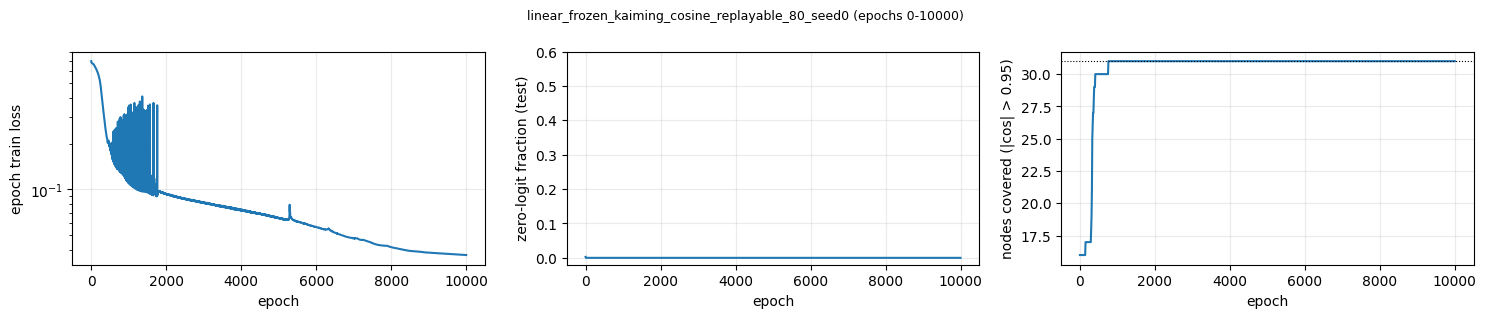

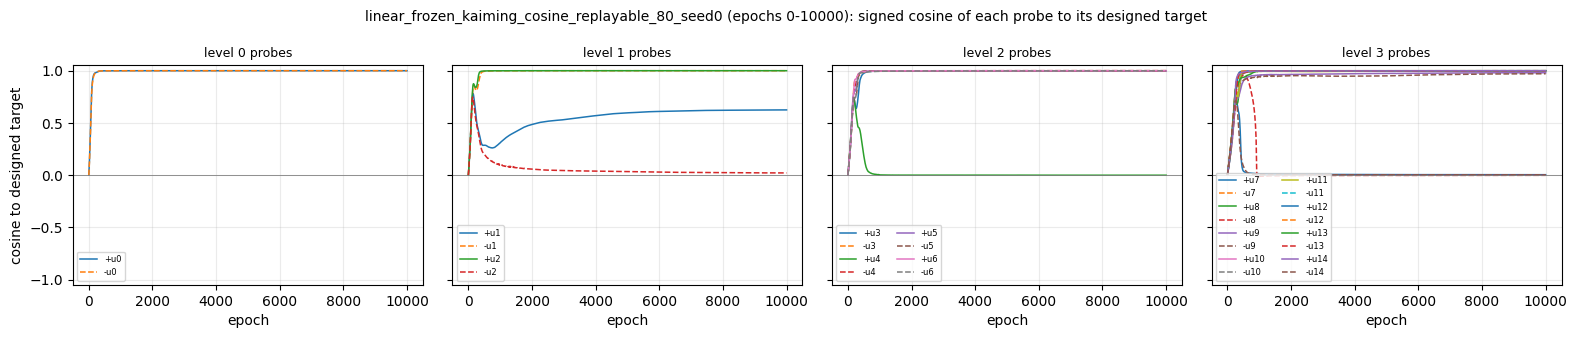

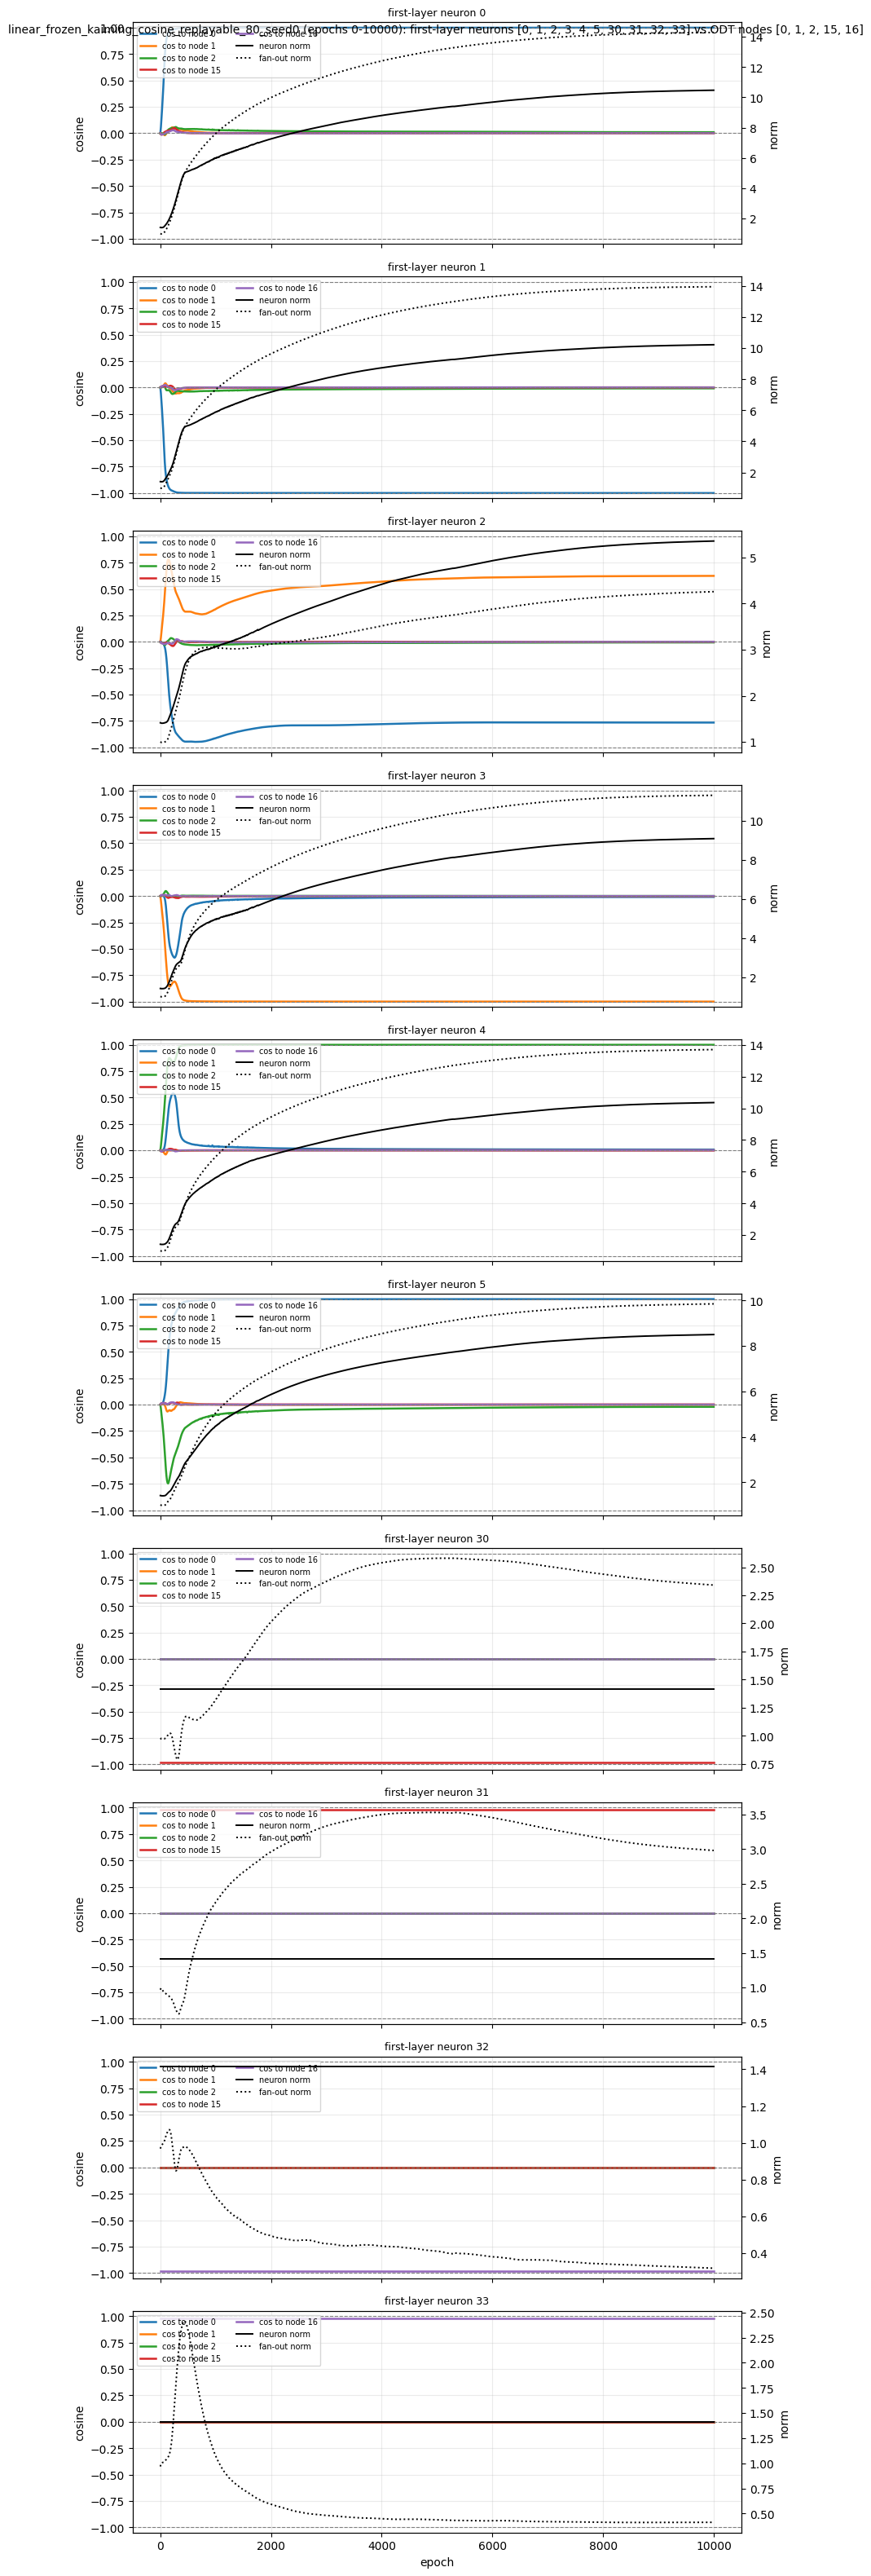

In [3]:
NEURON_IDS = [0, 1, 2, 3, 4, 5,30,31,32,33]
series11 = trajectory_plots(run11, NEURON_IDS, node_ids=None, start_epoch=0, end_epoch=10000)        # x-axis: 100-step epochs


Visible edges: 3552 / 3640
First-layer aligned nodes: 73 / 80


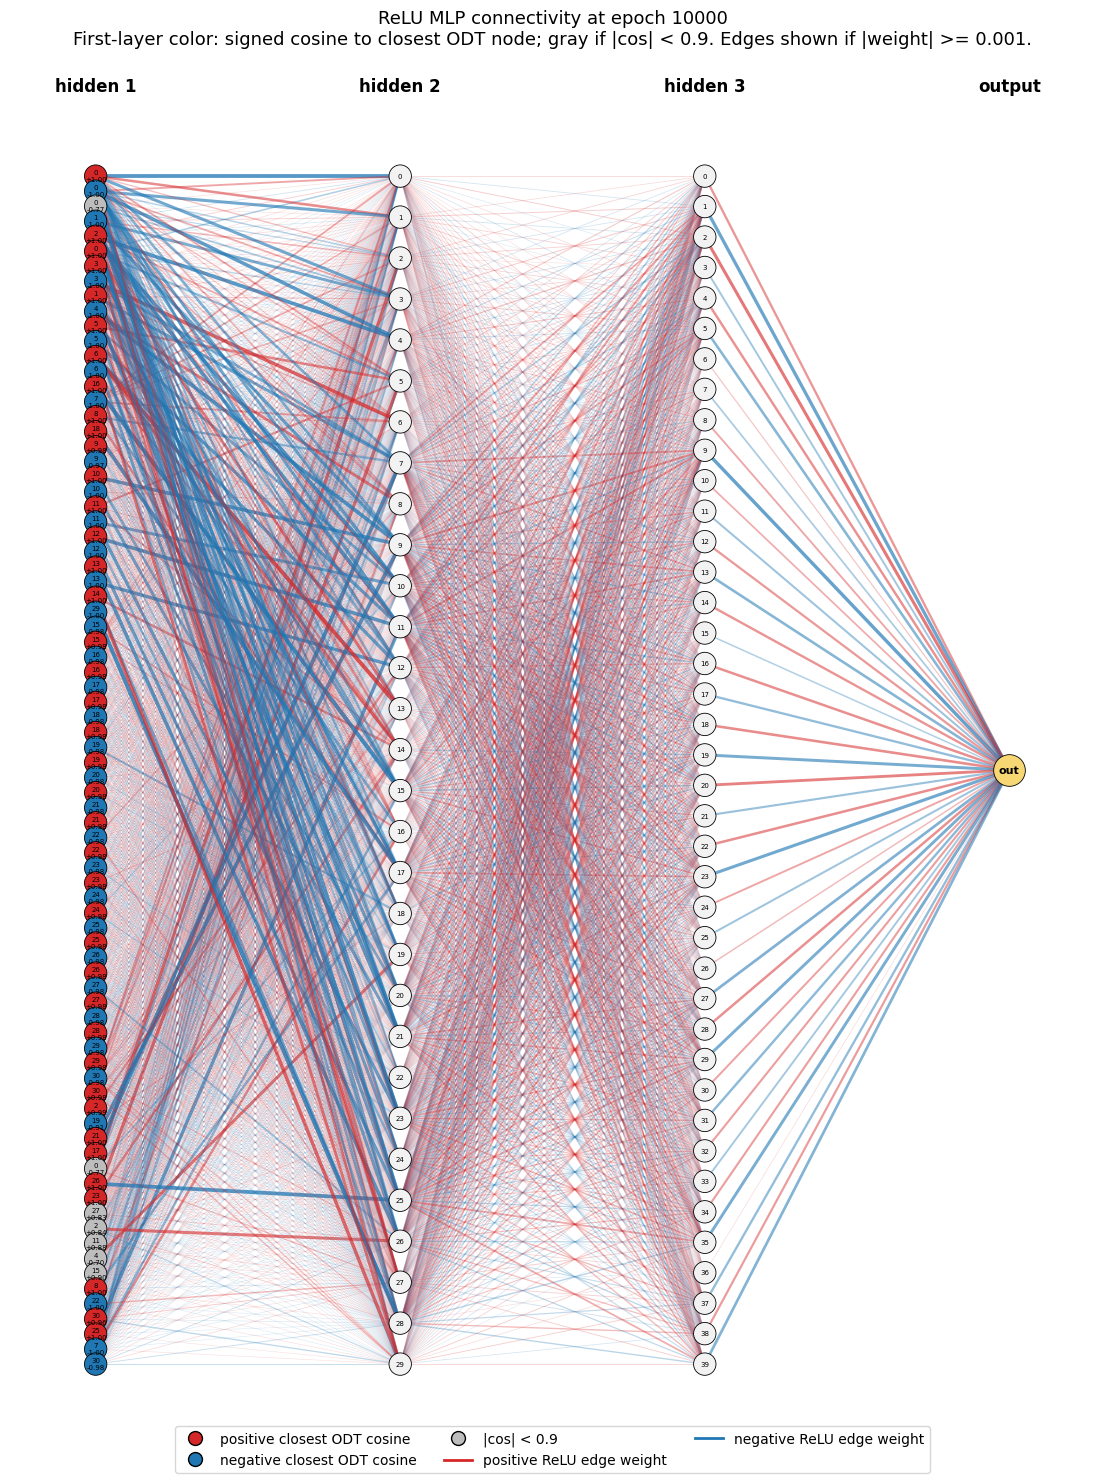

,row,group,designed_target,closest_node,level,signed_cos,norm
0,1,probe,"(0, -1)",0,0,-1.000,10.22
1,0,probe,"(0, 1)",0,0,1.000,10.47
2,5,probe,"(2, -1)",0,0,1.000,8.50
3,3,probe,"(1, -1)",1,1,-1.000,9.09
4,8,probe,"(4, 1)",1,1,1.000,6.93
...,...,...,...,...,...,...,...
68,59,cue,,29,4,0.981,1.41
69,60,cue,,30,4,-0.981,1.41
70,79,random,,30,4,-0.977,2.22
71,76,random,,30,4,0.960,2.05


In [6]:
GRAPH_EPOCH = 10000   # 100-step epochs: 1000 = step 100k, when all 15 internal nodes are on their probes
mask_arg =  [np.zeros(run11["dims"][0], dtype=bool), np.zeros(run11["dims"][1], dtype=bool), np.ones(run11["dims"][2], dtype=bool)]
mask_arg[0][0:]=1
mask_arg[1][0:]=1
table11 = network_view(run11, GRAPH_EPOCH, align_threshold=0.9, edge_threshold=0.001, mask_arg=mask_arg)


## 12. Run 11 with the probe rows scaled by 0.01 at init (replayable)

| setting | value |
|---|---|
| change from run 11 | **the 30 probe rows multiplied by 0.01 at init** (`probe_scale=0.01`, applied after the Kaiming row rescale); cues, random rows and layers 2-4 identical |
| everything else | run 11: 1M points, batch 10k (epoch = 100 steps), 10 000 epochs, lr 0.01 -> 0.0005, momentum 0.9, weights and momentum every 1000 steps, cues frozen |
| logit RMS at init | 0.003 |
| wall time | 26 min |
| storage | `results/designed_init/hierarchy_replayable_probe001/replay/` |
| script | `run_hierarchy_replayable_probe001.py` |
| in git | summary and per-epoch table only: the replay files are **not committed** (repository size budget), regenerate them with the script before running the cells below |

**Findings.**
- Early capture is faster: the root pair reaches cosine 0.95 at step 5k (run 11: 15-16k), -u_1 and +u_2 at 17-19k (37k, 32k); a small row rotates faster for the same push. Loss 0.3 at step 41k (run 11: 34k), then the run lags: 0.19 at 100k and 0.125 at 500k vs 0.113 and 0.065.
- Hierarchy capture is a little worse: 14 of 15 internal nodes on their own probes at the intended pole from step 100k (node 8 missed), 17 of 30 probes at the intended pole at the end (run 11: 15 / 24), 0 opposite, all 31 nodes covered from 100k; no unit path changed sign, but 14 units dropped their probe entry (run 11: 8).
- Late collapse: from step 300k the third layer dies progressively (units never active on a 100k test sample: 3 at 300k, 15 at 400k, 23 at 500k, 36 of 40 at the end; active fraction 1.0 -> 0.54 -> 0.05 -> 0), with loss spikes at ~400k (0.73) and a moment at step ~600k where every logit is zero (loss 0.693). The net then settles into the half-dead solution: zero logits on the negative class, loss floor 0.38, default-rule test error 50%, strict-rule 3.4%.
- What differs: with the probes near zero the second-layer units are gated by their cue blocks alone and fire on ~74% of inputs throughout (run 11: ~35%); the denser second-layer activity goes with larger second-layer weights (|W2| 60 vs 47) and a third layer whose pre-activations drift negative. So a 0.01 probe scale buys faster first-layer capture at the price of a different, denser second-layer representation and, eventually, dead third-layer units. The replay files allow the death of individual third-layer units to be traced step by step.


In [ ]:
from layer_lenses.relu_analysis import load_designed_run
sr12 = load_designed_run(RESULTS / "hierarchy_replayable_probe001" / "replay")          # ~20 s
_out = sr12["out"]; _ep = np.array(sorted(_out["checkpoint_snapshots"]))
run12 = {"tag": sr12["tag"], "dims": [80, 30, 40], "epochs": _ep, "losses": np.array(_out["epoch_losses"]), "lr": np.array(_out["lr_history"]),
         "W": {key: np.stack([_out["checkpoint_snapshots"][e][key].numpy() for e in _ep]) for key in _out["checkpoint_snapshots"][_ep[0]]},
         "per_epoch": pd.read_csv(RESULTS / "hierarchy_replayable_probe001" / f"per_epoch_{sr12['tag']}.csv"), "summary": pd.read_csv(RESULTS / "hierarchy_replayable_probe001" / "summary.csv").iloc[0]}
summary12 = findings_table(run12)
NEURON_IDS = [0, 1, 2, 3, 4, 5]
series12 = trajectory_plots(run12, NEURON_IDS, node_ids=None)        # x-axis: 100-step epochs


In [ ]:
GRAPH_EPOCH = 1000   # 100-step epochs; 1000 = step 100k
table12 = network_view(run12, GRAPH_EPOCH, align_threshold=0.5, edge_threshold=0.5)


In [ ]:
# Third-layer death in run 12 vs run 11: fraction of third-layer units never active on 100k test points, and the active fractions of layers 2 and 3, by snapshot.
from layer_lenses.relu_mlp import ReLUMLP
Xd = torch.from_numpy(x_test).float()
rows_d = []
for lab, rr in (("run 11", run11), ("run 12", run12)):
    for e in (100, 500, 1000, 2000, 3000, 3500, 4000, 4500, 5000, 5500, 6000, 7000, 10000):
        sd = snapshot_state_dict(rr, e); m = ReLUMLP(input_dim=100, hidden_dims=[80, 30, 40], bias=False); m.load_state_dict(sd); m.eval()
        with torch.no_grad():
            h2 = torch.relu(m.hidden_layers[1](torch.relu(m.hidden_layers[0](Xd)))); h3 = torch.relu(m.hidden_layers[2](h2)); o = m.output_layer(h3).reshape(-1).numpy()
        rows_d.append({"run": lab, "step": e * 100, "loss": round(float(rr["losses"][e - 1]), 3), "l2 active frac": round(float((h2 > 0).float().mean()), 3), "l3 active frac": round(float((h3 > 0).float().mean()), 3),
                       "l3 dead units": int(((h3 > 0).float().mean(0) == 0).sum()), "zero-logit frac": round(float((o == 0).mean()), 3), "|W2|": round(float(np.linalg.norm(sd["hidden_layers.1.weight"].numpy())), 1), "|wo|": round(float(np.linalg.norm(sd["output_layer.weight"].numpy())), 1)})
dead = pd.DataFrame(rows_d); display(dead.pivot(index="step", columns="run", values=["loss", "l2 active frac", "l3 active frac", "l3 dead units", "zero-logit frac", "|W2|", "|wo|"]))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for lab, g in dead.groupby("run", sort=False):
    ls = "--" if lab == "run 11" else "-"
    axes[0].plot(g.step, g["l3 dead units"], ls=ls, marker="o", ms=3, label=lab); axes[1].plot(g.step, g["l3 active frac"], ls=ls, marker="o", ms=3, label=lab); axes[2].plot(g.step, g["zero-logit frac"], ls=ls, marker="o", ms=3, label=lab)
axes[0].set_ylabel("third-layer units never active"); axes[1].set_ylabel("third-layer active fraction"); axes[2].set_ylabel("zero-logit fraction (test)")
for ax in axes: ax.set_xlabel("step"); ax.grid(alpha=0.25); ax.legend(fontsize=7)
fig.tight_layout(); plt.show()


## 13. Branch of run 11 at epoch 750: first layer frozen, SGD momentum continued

| setting | value |
|---|---|
| branch point | run 11's epoch-750 checkpoint (step 75k): weights and SGD momentum from the replay files; the first layer at that point has 30 of 31 nodes covered (node 9's +u_9 probe at cosine 0.93) |
| first layer | **frozen** from epoch 750 (all 80 rows, update mask) |
| data / batch / epochs | run 11's: 1M points, batch 10k (epoch = 100 steps), epochs 750-10 000 |
| checkpoints | weights and full optimizer state every 10 epochs from 750; every interval replays exactly |
| optimizer | SGD momentum 0.9 **continued from run 11's momentum buffers**, lr 0.01 cosine schedule resumed at epoch 750 (identical to run 11's) |
| wall time | 24 min |
| storage | `results/designed_init/hierarchy_branch750_sgd_frozenL1/replay/` |
| script | `run_hierarchy_branch750.py` |
| in git | summary and per-epoch table only: the replay files are **not committed** (repository size budget), regenerate them with the script before running the cells below |

**Findings.**
- The loss spikes disappear although the sharpness does not: lr*lambda stays at 3.3-3.6 with the top eigenvector in layers 2-3 exactly as in run 11, yet the per-epoch loss std over epochs 750-1250 is 0.003 against 0.041 (0.002 vs 0.043 over 1000-1500). The period-2 oscillation in layers 2-3 is still there; the catapults needed a trainable first layer.
- In run 11 the first-layer motion after epoch 750 is concentrated in the random rows (rows 63, 69, 77 rotate 74-91 degrees as they get recruited to level-4 nodes; probes move 2-6 degrees), and the per-window first-layer movement has rank correlation ~0.75 with the loss std of the window; random row 69 is the fastest-moving row in most of the spikiest windows.
- The price of the freeze: loss 0.094 and test error 3.9% at the end (run 11: 0.037, 1.6%); 0.1 reached only at epoch 5565. Run 11's late first-layer refinement (random rows recruited, probe norms x1.8) is what takes the loss below 0.09.


In [ ]:
sr13 = load_designed_run(RESULTS / "hierarchy_branch750_sgd_frozenL1" / "replay")          # ~20 s
_out = sr13["out"]; _ep = np.array(sorted(_out["checkpoint_snapshots"]))
run13 = {"tag": sr13["tag"], "dims": [80, 30, 40], "epochs": _ep, "losses": np.array(_out["epoch_losses"]), "lr": np.array(_out["lr_history"]),
         "W": {key: np.stack([_out["checkpoint_snapshots"][e][key].numpy() for e in _ep]) for key in _out["checkpoint_snapshots"][_ep[0]]},
         "per_epoch": pd.read_csv(RESULTS / "hierarchy_branch750_sgd_frozenL1" / f"per_epoch_{sr13['tag']}.csv"), "summary": pd.read_csv(RESULTS / "hierarchy_branch750_sgd_frozenL1" / "summary.csv").iloc[0]}
summary13 = findings_table(run13)


In [ ]:
NEURON_IDS = [0, 1, 2, 3]
series13 = trajectory_plots(run13, NEURON_IDS, node_ids=None, start_epoch=750, end_epoch=2000)        # first layer frozen: the row plots are flat by construction


In [ ]:
GRAPH_EPOCH = 10000   # 100-step epochs
table13 = network_view(run13, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.5)


## 14. Branch of run 11 at epoch 750: first layer frozen, layers 2-4 trained with AdamW

| setting | value |
|---|---|
| branch point | run 11's epoch-750 checkpoint (step 75k): weights and SGD momentum from the replay files; the first layer at that point has 30 of 31 nodes covered (node 9's +u_9 probe at cosine 0.93) |
| first layer | **frozen** from epoch 750 (all 80 rows, update mask) |
| data / batch / epochs | run 11's: 1M points, batch 10k (epoch = 100 steps), epochs 750-10 000 |
| checkpoints | weights and full optimizer state every 10 epochs from 750; every interval replays exactly |
| optimizer | **AdamW (weight decay 0) from a fresh state**, lr 1e-3 on the same cosine shape resumed at epoch 750 (eta_min ratio 0.05, T_max 10 000); first layer still frozen |
| wall time | 26 min |
| storage | `results/designed_init/hierarchy_branch750_adam_frozenL1/replay/` |
| script | `run_hierarchy_branch750.py` |
| in git | summary and per-epoch table only: the replay files are **not committed** (repository size budget), regenerate them with the script before running the cells below |

**Findings.**
- Same plateau as the SGD branch, reached faster: loss 0.1 at epoch 3457 (SGD branch 5565), final 0.092, test error 3.85%. With the first layer fixed, the two optimizers find essentially the same end point.
- Smoothest of the three: per-epoch loss std 0.004 over epochs 750-1250, then 0.001 or less. The raw sharpness it tolerates grows to 1570 at the end (run 11: 1917 at lr 0.0005; the SGD branch 775), the top eigenvector 80% in layer 2.
- Adam grows the second layer more (|W2| 63 vs 40 for the SGD branch, |W3| 35 vs 30) for the same loss; the level-4 'second wave' seen with Adam in random-init runs cannot happen here because the first layer is frozen.


In [ ]:
sr14 = load_designed_run(RESULTS / "hierarchy_branch750_adam_frozenL1" / "replay")          # ~20 s
_out = sr14["out"]; _ep = np.array(sorted(_out["checkpoint_snapshots"]))
run14 = {"tag": sr14["tag"], "dims": [80, 30, 40], "epochs": _ep, "losses": np.array(_out["epoch_losses"]), "lr": np.array(_out["lr_history"]),
         "W": {key: np.stack([_out["checkpoint_snapshots"][e][key].numpy() for e in _ep]) for key in _out["checkpoint_snapshots"][_ep[0]]},
         "per_epoch": pd.read_csv(RESULTS / "hierarchy_branch750_adam_frozenL1" / f"per_epoch_{sr14['tag']}.csv"), "summary": pd.read_csv(RESULTS / "hierarchy_branch750_adam_frozenL1" / "summary.csv").iloc[0]}
summary14 = findings_table(run14)


In [ ]:
NEURON_IDS = [0, 1, 2, 3]
series14 = trajectory_plots(run14, NEURON_IDS, node_ids=None, start_epoch=750, end_epoch=2000)        # first layer frozen: the row plots are flat by construction


In [ ]:
GRAPH_EPOCH = 10000   # 100-step epochs
table14 = network_view(run14, GRAPH_EPOCH, align_threshold=0.5, edge_threshold=0.5)


In [ ]:
# Runs 11, 13, 14 side by side from epoch 750: loss, per-500-epoch loss std, and run 11's first-layer motion per 10 epochs vs its loss spikes.
three = {"run 11 (free first layer)": run11, "run 13 (SGD, frozen L1)": run13, "run 14 (AdamW, frozen L1)": run14}
fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
for lab, rr in three.items():
    L = rr["losses"]; ep_ = np.arange(1, len(L) + 1); sel = ep_ >= 750
    axes[0].plot(ep_[sel], L[sel], lw=0.5, label=lab)
    w = [(a, float(np.nanstd(L[a:a + 500]))) for a in range(750, 9500, 250)]; axes[1].plot([a for a, _ in w], [s for _, s in w], marker="o", ms=2.5, label=lab)
axes[0].set_yscale("log"); axes[0].set_ylabel("epoch train loss"); axes[1].set_yscale("log"); axes[1].set_ylabel("loss std over the next 500 epochs")
W = run11["W"]["hidden_layers.0.weight"]; ep11 = run11["epochs"]; free = np.r_[0:30, 62:80]; i0 = int(np.nonzero(ep11 == 750)[0][0]); i1 = int(np.nonzero(ep11 == 3000)[0][0])
rot, lstd, xs = [], [], []
for i in range(i0, i1):
    a, b = W[i], W[i + 1]; r = np.degrees(np.arccos(np.clip((a * b).sum(1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1)), -1, 1)))[free].max()
    e = int(ep11[i]); rot.append(r); lstd.append(float(run11["losses"][e:e + 10].std())); xs.append(e)
ax2 = axes[2]; ax2.plot(xs, rot, lw=0.8, color="C0", label="run 11: max first-layer row rotation per 10 epochs (deg)"); ax2.set_ylabel("degrees", color="C0")
ax3 = ax2.twinx(); ax3.plot(xs, lstd, lw=0.8, color="C3", label="run 11: loss std of those 10 epochs"); ax3.set_ylabel("loss std", color="C3")
for ax in axes: ax.set_xlabel("epoch (100 steps)"); ax.grid(alpha=0.25)
axes[0].legend(fontsize=7); axes[1].legend(fontsize=7); h1, l1 = ax2.get_legend_handles_labels(); h2, l2 = ax3.get_legend_handles_labels(); ax2.legend(h1 + h2, l1 + l2, fontsize=6)
fig.tight_layout(); plt.show()
print("rank correlation over 10-epoch windows, epochs 750-3000, between run 11's max row rotation and its loss std:", round(float(pd.Series(rot).rank().corr(pd.Series(lstd).rank())), 2))


## 15. Branch of run 11 at epoch 750: all layers trained with AdamW (nothing frozen but the cues)

| setting | value |
|---|---|
| branch point | run 11's epoch-750 checkpoint (step 75k), same as runs 13-14 |
| first layer | **free** (only the 32 cue rows frozen, as in run 11) |
| data / batch / epochs | run 11's: 1M points, batch 10k (epoch = 100 steps), epochs 750-10 000 |
| checkpoints | weights and full Adam state every 10 epochs from 750; every interval replays exactly |
| optimizer | **AdamW (weight decay 0) from a fresh state on all layers**, lr 1e-3 on the same cosine shape resumed at epoch 750 (eta_min ratio 0.05, T_max 10 000) |
| wall time | 37 min (shared GPU with run 16) |
| storage | `results/designed_init/hierarchy_branch750_adam_all/replay/` |
| script | `run_hierarchy_branch750_adam_all.py` |

**Findings.**
- Best end point of all runs: loss 0.019, test error 1.0% (run 11: 0.037 / 1.6%; runs 13-14 with the first layer frozen: 0.093 / 3.9%). Loss 0.1 at epoch 808 (run 11: 1222), 0.05 at 3199, 0.03 at 6794.
- No catapults: the largest epoch loss after the branch is the one at epoch 750 itself; loss std over epochs 750-1250 is 0.014 (run 11: 0.041) and 0.003 over 1000-1500 (run 11: 0.043). Adam's per-coordinate normalisation does not sit at the heavy-ball stability limit of the stiff layer-2/3 directions that run 11 oscillates across.
- The first layer moves as much as in run 11 (probe rotation from 750 to the end: median 5 degrees vs 4; random rows 34 vs 27 degrees) and ends with the same row-to-node assignment (31 nodes covered from epoch 760 on, node 9 by its own probe pair at cosine 0.98). Norms grow more: probes 3.1 -> 6.7 (run 11: 5.7), random rows 2.1 -> 5.9 (4.0), |W2| 23 -> 267 (run 11: 47), |W3| 20 -> 77 (35).
- Against run 14 (same optimizer switch, first layer frozen, loss 0.092): the free first layer is worth the whole difference. The late first-layer refinement (random-row recruitment, norm growth) is what both frozen branches lacked, and Adam does it without the spikes.


In [ ]:
sr15 = load_designed_run(RESULTS / "hierarchy_branch750_adam_all" / "replay")          # ~20 s
_out = sr15["out"]; _ep = np.array(sorted(_out["checkpoint_snapshots"]))
run15 = {"tag": sr15["tag"], "dims": [80, 30, 40], "epochs": _ep, "losses": np.array(_out["epoch_losses"]), "lr": np.array(_out["lr_history"]),
         "W": {key: np.stack([_out["checkpoint_snapshots"][e][key].numpy() for e in _ep]) for key in _out["checkpoint_snapshots"][_ep[0]]},
         "per_epoch": pd.read_csv(RESULTS / "hierarchy_branch750_adam_all" / f"per_epoch_{sr15['tag']}.csv"), "summary": pd.read_csv(RESULTS / "hierarchy_branch750_adam_all" / "summary.csv").iloc[0]}
summary15 = findings_table(run15)

In [ ]:
NEURON_IDS = [0, 1, 2, 3]
series15 = trajectory_plots(run15, NEURON_IDS, node_ids=None, start_epoch=750, end_epoch=3000)

In [ ]:
GRAPH_EPOCH = 10000   # 100-step epochs
table15 = network_view(run15, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.5)

## 16. Run 11 with a per-neuron rotation lock on the first layer (|cos| 0.99)

| setting | value |
|---|---|
| init / data / optimizer | identical to run 11 (80-30-40, balanced output, path-sign cues, inv_sqrt cue blocks, balanced +-10-quanta paths; 1M points, batch 10k, 10 000 epochs of 100 steps; SGD momentum 0.9, lr 0.01 -> 0.0005 cosine; cues frozen) |
| rotation lock | each of the 48 trainable first-layer rows (30 probes, 18 random rows) trains freely until `|cos(row, u_j)| >= 0.99` for some ODT normal; from then on every update is projected onto the row's own direction at the moment of locking (`FirstLayerRotationLock`, `rotation_lock=` in `relu_training_step`), so the row can only grow or shrink |
| checkpoints | weights, momentum and the lock state (`rotation_lock.npz`) every 10 epochs; `replay_interval_from_snapshot` replays any interval exactly and returns `locked_rows` per step |
| wall time | 48 min (shared GPU with run 15) |
| storage | `results/designed_init/hierarchy_rotlock099/replay/`, lock times in `lock_table_*.csv` |
| script | `run_hierarchy_rotlock.py` |

**Findings.**
- Lock timeline: 11 rows locked by epoch 500, 25 by 750, 33 by 2000, 35 of 48 at the end (26 of the 30 probes, 9 of the 18 random rows). Probe lock epochs run from 268 to 4474 with the bulk between 400 and 750, i.e. the lock fires during the capture phase that in run 11 precedes the loss spikes.
- Loss floor: 0.112 at the end (test error 4.7%), never below 0.1; run 11 is at 0.113 already at epoch 1000 and ends at 0.037. The same plateau level as the frozen-first-layer branches (runs 13-14: 0.093).
- No spikes after epoch 750 (largest epoch loss 0.178 at epoch 859; loss std over 750-1250 0.006 vs run 11's 0.041) although 13 rows were still rotating freely. Consistent with runs 13-14: the catapults need the captured rows to keep rotating.
- Row-to-node assignment is mostly run 11's, including the same substitutes (row 3 -> -u_1, row 5 -> +u_0, row 8 -> +u_1, row 14 -> u_16, row 29 -> u_29). Differences: row 2 locks onto -u_0 at epoch 2041 (in run 11 it drifts to -u_0 at cosine -0.77 without ever passing 0.95); node 0 ends with 8 rows (random rows 66, 69, 72 lock onto +-u_0 and 75, 77 sit at 0.91 / 0.98); node 9 is never covered because its probe pair stalls at cosine 0.95 / 0.94, under the threshold (run 11: 0.98); row 17 ends near -u_8 (0.985, unlocked) instead of u_18.
- What the lock costs: a row is frozen at |cos| = 0.99 exactly, 8.1 degrees off the hyperplane, for good; run 11's captured probes end at mean |cos| 0.998. Snapping rows onto the normals after the fact does not isolate this (layers 2-4 co-adapt to the exact row directions; snapping even run 11's rows raises its loss to 1.1), so the comparison with run 11 is the measure.
- Possible variants: lock onto the target normal itself (snap at the crossing), a higher threshold (0.999), or lock when the rotation rate drops instead of at a cosine level.


In [ ]:
sr16 = load_designed_run(RESULTS / "hierarchy_rotlock099" / "replay")          # ~20 s
_out = sr16["out"]; _ep = np.array(sorted(_out["checkpoint_snapshots"]))
run16 = {"tag": sr16["tag"], "dims": [80, 30, 40], "epochs": _ep, "losses": np.array(_out["epoch_losses"]), "lr": np.array(_out["lr_history"]),
         "W": {key: np.stack([_out["checkpoint_snapshots"][e][key].numpy() for e in _ep]) for key in _out["checkpoint_snapshots"][_ep[0]]},
         "per_epoch": pd.read_csv(RESULTS / "hierarchy_rotlock099" / f"per_epoch_{sr16['tag']}.csv"), "summary": pd.read_csv(RESULTS / "hierarchy_rotlock099" / "summary.csv").iloc[0]}
summary16 = findings_table(run16)
lock16 = pd.read_csv(RESULTS / "hierarchy_rotlock099" / f"lock_table_{sr16['tag']}.csv")      # row, lock_step, lock_epoch, locked_node (-1 = never locked), locked_node_cos
fig, ax = plt.subplots(figsize=(7, 2.8)); ax.plot(run16["per_epoch"].epoch, run16["per_epoch"].n_locked, label="locked rows (of 48)"); ax.plot(run16["per_epoch"].epoch, run16["per_epoch"].n_locked_probes, label="locked probes (of 30)")
ax.set_xlabel("epoch (100 steps)"); ax.set_xscale("log"); ax.grid(alpha=0.25); ax.legend(); plt.show()
print(lock16[lock16.lock_step >= 0].sort_values("lock_epoch").to_string(index=False))

In [ ]:
NEURON_IDS = [0, 1, 2, 3]
series16 = trajectory_plots(run16, NEURON_IDS, node_ids=None, start_epoch=750, end_epoch=2000)      # cosines flatten at exactly 0.99 once a row locks; only the norm keeps moving

In [ ]:
GRAPH_EPOCH = 10000   # 100-step epochs
table16 = network_view(run16, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.5)

In [ ]:
# Runs 11, 13-16 from epoch 750: loss and per-500-epoch loss std.
five = {"run 11 (SGD, free)": run11, "run 13 (SGD, frozen L1)": run13, "run 14 (AdamW, frozen L1)": run14, "run 15 (AdamW, free)": run15, "run 16 (SGD, rotation lock)": run16}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for lab, rr in five.items():
    L = rr["losses"]; ep_ = np.arange(1, len(L) + 1); sel = ep_ >= 750
    axes[0].plot(ep_[sel], L[sel], lw=0.5, label=lab)
    w = [(a, float(np.nanstd(L[a:a + 500]))) for a in range(750, 9500, 250)]; axes[1].plot([a for a, _ in w], [s for _, s in w], marker="o", ms=2.5, label=lab)
axes[0].set_yscale("log"); axes[0].set_ylabel("epoch train loss"); axes[1].set_yscale("log"); axes[1].set_ylabel("loss std over the next 500 epochs")
for ax in axes: ax.set_xlabel("epoch (100 steps)"); ax.grid(alpha=0.25); ax.legend(fontsize=7)
fig.tight_layout(); plt.show()
print(pd.DataFrame({lab: {f"{a}-{a+500}": f"{np.nanmean(rr['losses'][a:a+500]):.3f} / {np.nanstd(rr['losses'][a:a+500]):.4f}" for a in (750, 1000, 2000, 5000, 9500)} for lab, rr in five.items()}).T.to_string())

## 17. Run 11 trained with ScalarAdam: SGD-momentum direction, scalar-normalised step (base lr 0.001)

| setting | value |
|---|---|
| init / data / schedule | identical to run 11 (80-30-40 hierarchy design, cues frozen; 1M points, batch 10k, 10 000 epochs of 100 steps; cosine to 0.05x) |
| optimizer | `ScalarAdam`: `m = 0.9 m + 0.1 g` per parameter, `v = 0.999 v + 0.001 |g|^2` one scalar over all parameters, step `-lr * m_hat / (sqrt(v_hat) + eps)`; base lr 0.001, so the step is at most ~0.001 in parameter space. `lr_eff = lr / rms|g|` below; because `m` is the (1 - beta1)-scaled form of SGD's momentum buffer, the SGD-equivalent learning rate is `0.1 * lr_eff` and the heavy-ball limit 2(1+beta) = 3.8 reads `lr_eff * lambda < 38` |
| checkpoints | weights and the full optimizer state every 10 epochs; every interval replays exactly |
| diagnostics | per epoch: rms gradient norm and lr_eff from the optimizer state; every 100 epochs: lambda_max on 20k points (`top_hessian_eigenvalue`) and lr_eff * lambda_max |
| wall time | 32 min |
| storage | `results/designed_init/hierarchy_scalaradam/replay/` |
| script | `run_hierarchy_scalaradam.py` |

**Findings.**
- No stability phenomena at all: lr_eff * lambda_max peaks at 0.35, i.e. 0.035 in SGD-equivalent units (run 11 sits at 3.5-3.8 of the limit 3.8), the detrended loss residual has std 0.0000 over epochs 500-3000 (run 11: 0.026) and the largest one-epoch loss change is 0.001 (run 11: 0.31).
- It follows run 11's path: at every checkpoint the first layer is within 0.06-0.39 of run 11's nearest checkpoint while having travelled up to 17 from the init, and the nodes are captured in the same order (0, 6, 4, 2/14, 3/5, 7, 12, 10, 13, 1, 11, 8, 9) with the same substitutes (row 5 -> +u_0, row 8 -> +u_1, row 14 -> u_16, row 29 -> u_29). So the normalised step re-parametrises run 11's time without changing the trajectory, which is what the small-lr limit should do.
- But the clock is slow and the cosine decay stops it early: epoch 10 000 of this run corresponds to epoch ~400 of run 11 (loss 0.22 vs run 11's 0.037; 30 of 31 nodes, node 9 at 0.83 / 0.88). The capture phase runs from epoch 2300 to 7900 instead of 300-760. The reason is the plateau escape: run 11's step grows with the gradient (0.0016 at init to 0.005 by epoch 300 and 0.018 in the capture phase), the normalised step is capped at lr, so the exponential escape from the init plateau becomes a crawl at constant speed, and by the time the gradient is large the schedule has decayed lr_eff to 1e-4.
- Sharpness grows steadily with capture (lambda_max 0.4 -> 312, 83% of the eigenvector in W2) with no learning-rate constraint acting, i.e. the lambda ~ 300-400 at which run 11 sits on the edge is the geometry of the captured solution, not something the edge creates.
- To reach run 11's end on the same path: base lr 0.003 with no cosine decay (run 18), or lr 0.001 constant for ~3x the epochs.


In [ ]:
sr17 = load_designed_run(RESULTS / "hierarchy_scalaradam" / "replay")          # ~20 s
_out = sr17["out"]; _ep = np.array(sorted(_out["checkpoint_snapshots"]))
run17 = {"tag": sr17["tag"], "dims": [80, 30, 40], "epochs": _ep, "losses": np.array(_out["epoch_losses"]), "lr": np.array(_out["lr_history"]),
         "W": {key: np.stack([_out["checkpoint_snapshots"][e][key].numpy() for e in _ep]) for key in _out["checkpoint_snapshots"][_ep[0]]},
         "per_epoch": pd.read_csv(RESULTS / "hierarchy_scalaradam" / f"per_epoch_{sr17['tag']}.csv"), "summary": pd.read_csv(RESULTS / "hierarchy_scalaradam" / "summary.csv").iloc[0]}
summary17 = findings_table(run17)
pe17 = run17["per_epoch"]; fig, axes = plt.subplots(1, 3, figsize=(16, 3.2))
axes[0].plot(pe17.epoch, pe17.lr_eff, label="lr_eff = lr / rms|g|"); axes[0].plot(pe17.epoch, pe17.lr, ls="--", label="base lr (cosine)"); axes[0].set_yscale("log"); axes[0].legend(fontsize=7)
s_ = pe17.dropna(subset=["lambda_max"]); axes[1].plot(s_.epoch, s_.lambda_max, marker="o", ms=2.5); axes[1].set_ylabel("lambda_max (20k points)")
axes[2].plot(s_.epoch, s_.lr_eff_x_lambda, marker="o", ms=2.5); axes[2].axhline(38, color="r", ls="--", lw=0.8, label="heavy-ball limit 2(1+beta)/(1-beta) in lr_eff units"); axes[2].set_ylabel("lr_eff * lambda_max"); axes[2].set_yscale("log"); axes[2].legend(fontsize=7)
for ax in axes: ax.set_xlabel("epoch (100 steps)"); ax.grid(alpha=0.25)
fig.tight_layout(); plt.show()

In [ ]:
NEURON_IDS = [0, 1, 2, 3]
series17 = trajectory_plots(run17, NEURON_IDS, node_ids=None)

In [ ]:
GRAPH_EPOCH = 10000   # 100-step epochs
table17 = network_view(run17, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.5)

In [ ]:
# Same path, different clock: for each run 17 checkpoint, the run 11 checkpoint nearest in first-layer parameter space, and the distance to it.
W11_, W17_ = run11["W"]["hidden_layers.0.weight"], run17["W"]["hidden_layers.0.weight"]; e11_, e17_ = run11["epochs"], run17["epochs"]
near, dist, trav = [], [], []
for i in range(len(e17_)):
    d = np.linalg.norm((W11_ - W17_[i]).reshape(len(e11_), -1), axis=1); j = int(d.argmin()); near.append(e11_[j]); dist.append(d[j]); trav.append(np.linalg.norm(W17_[i] - W11_[0]))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].plot(e17_, near); axes[0].set_xlabel("run 17 epoch"); axes[0].set_ylabel("nearest run 11 epoch (first layer)")
axes[1].plot(e17_, dist, label="distance to the nearest run 11 checkpoint"); axes[1].plot(e17_, trav, ls="--", label="distance travelled from the init"); axes[1].set_yscale("log"); axes[1].legend(fontsize=7); axes[1].set_xlabel("run 17 epoch")
for ax in axes: ax.grid(alpha=0.25)
fig.tight_layout(); plt.show()
print("run 17 epoch 10000 lands near run 11 epoch", near[-1], "at first-layer distance", round(dist[-1], 2), "after travelling", round(trav[-1], 1))

## 18. ScalarAdam, base lr 0.003, constant (no decay)

| setting | value |
|---|---|
| everything | run 17 (run 11's init, data, 10 000 epochs of 100 steps, cues frozen, `ScalarAdam` betas 0.9 / 0.999) except base lr **0.003** and **no cosine decay** (eta_min ratio 1.0) |
| step | at most ~0.003 in parameter space; SGD-equivalent rate `0.1 * lr_eff`, limit `lr_eff * lambda < 38` |
| wall time | 39 min |
| storage | `results/designed_init/hierarchy_scalaradam_lr003/replay/` |
| script | `run_hierarchy_scalaradam_lr003.py` |

**Findings.**
- Still perfectly smooth: detrended loss residual std 0.0000 over the whole run, largest one-epoch change 0.003, while lr_eff * lambda_max climbs steadily from 0.24 to 5.85 (0.6 in SGD-equivalent units, 15% of the limit). lambda_max reaches 2068 at the end (run 11: 1966 at its end, 380 at its edge), 83% of the eigenvector in W2 throughout; the sharpening tracks capture and norm growth, with no learning-rate constraint acting.
- Covers run 11's capture phase on the same path: 31 nodes by epoch 7460 (node 9 last, as in run 11), internal nodes captured at epochs 760-1760 in run 11's order (0, 6, 4, 14/2, 5/3, 7, 12, 10, 13, 1, 11, 8, 9), the same substitutes and the same random rows recruited (65, 67, 68, 74, 77, 78, 79 ...). The first layer stays within 0.1-0.4 of run 11's nearest checkpoint up to epoch 2000 (run 11's epoch 420) and drifts to 3.4 by the end (run 11's epoch 760), after travelling 24.
- Clock: epoch 10 000 of run 18 is run 11's epoch ~760, i.e. 2.5x slower through the capture phase and decelerating (rms|g| grows 0.04 -> 1.06, so lr_eff falls 0.067 -> 0.0028). End loss 0.096 (test error 3.9%; run 11 reads 0.157 at its epoch 760 because its oscillation inflates the loss); |W2| 22, |W3| 23 (run 11 at 750: 23, 20).
- Run 11's remaining path (first-layer distance 19 to its end, the late refinement that takes its loss from 0.09 to 0.037) is not reached; at the current speed it would need several times the epochs, or a larger base lr (0.01 would still be under a tenth of the limit at the end).


In [ ]:
sr18 = load_designed_run(RESULTS / "hierarchy_scalaradam_lr003" / "replay")          # ~20 s
_out = sr18["out"]; _ep = np.array(sorted(_out["checkpoint_snapshots"]))
run18 = {"tag": sr18["tag"], "dims": [80, 30, 40], "epochs": _ep, "losses": np.array(_out["epoch_losses"]), "lr": np.array(_out["lr_history"]),
         "W": {key: np.stack([_out["checkpoint_snapshots"][e][key].numpy() for e in _ep]) for key in _out["checkpoint_snapshots"][_ep[0]]},
         "per_epoch": pd.read_csv(RESULTS / "hierarchy_scalaradam_lr003" / f"per_epoch_{sr18['tag']}.csv"), "summary": pd.read_csv(RESULTS / "hierarchy_scalaradam_lr003" / "summary.csv").iloc[0]}
summary18 = findings_table(run18)
pe18 = run18["per_epoch"]; fig, axes = plt.subplots(1, 3, figsize=(16, 3.2))
axes[0].plot(pe18.epoch, pe18.lr_eff, label="lr_eff = lr / rms|g|"); axes[0].set_yscale("log"); axes[0].legend(fontsize=7)
s_ = pe18.dropna(subset=["lambda_max"]); axes[1].plot(s_.epoch, s_.lambda_max, marker="o", ms=2.5); axes[1].set_ylabel("lambda_max (20k points)")
axes[2].plot(s_.epoch, s_.lr_eff_x_lambda, marker="o", ms=2.5); axes[2].axhline(38, color="r", ls="--", lw=0.8, label="heavy-ball limit 2(1+beta)/(1-beta) in lr_eff units"); axes[2].set_ylabel("lr_eff * lambda_max"); axes[2].set_yscale("log"); axes[2].legend(fontsize=7)
for ax in axes: ax.set_xlabel("epoch (100 steps)"); ax.grid(alpha=0.25)
fig.tight_layout(); plt.show()

In [ ]:
NEURON_IDS = [0, 1, 2, 3]
series18 = trajectory_plots(run18, NEURON_IDS, node_ids=None)

In [ ]:
GRAPH_EPOCH = 10000   # 100-step epochs
table18 = network_view(run18, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.5)

In [ ]:
# Runs 11, 17, 18: loss vs epoch, and the run 11 epoch each ScalarAdam checkpoint is nearest to (first layer).
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for lab, rr in {"run 11 (SGD momentum, lr 0.01 cosine)": run11, "run 17 (ScalarAdam 0.001 cosine)": run17, "run 18 (ScalarAdam 0.003 const)": run18}.items():
    axes[0].plot(np.arange(1, len(rr["losses"]) + 1), rr["losses"], lw=0.6, label=lab)
axes[0].set_yscale("log"); axes[0].set_ylabel("epoch train loss"); axes[0].legend(fontsize=7)
W11_ = run11["W"]["hidden_layers.0.weight"]; e11_ = run11["epochs"]
for lab, rr in {"run 17": run17, "run 18": run18}.items():
    Wr = rr["W"]["hidden_layers.0.weight"]; near = [e11_[int(np.linalg.norm((W11_ - Wr[i]).reshape(len(e11_), -1), axis=1).argmin())] for i in range(len(rr["epochs"]))]
    axes[1].plot(rr["epochs"], near, label=lab)
axes[1].plot(e11_, e11_, color="gray", ls=":", lw=0.8, label="run 11 itself"); axes[1].set_ylabel("nearest run 11 epoch (first layer)"); axes[1].legend(fontsize=7); axes[1].set_yscale("log")
for ax in axes: ax.set_xlabel("epoch (100 steps)"); ax.grid(alpha=0.25)
fig.tight_layout(); plt.show()

## 19. ScalarAdam, base lr 0.01, constant

| setting | value |
|---|---|
| everything | run 18 with base lr **0.01** (constant); step at most ~0.01 in parameter space, SGD-equivalent rate `0.1 * lr_eff`, limit `lr_eff * lambda < 38` |
| wall time | 35 min |
| storage | `results/designed_init/hierarchy_scalaradam_lr01/replay/` |
| script | `run_hierarchy_scalaradam_lr01.py` |

**Findings.**
- Still smooth (detrended loss residual std 0.0000, largest one-epoch change 0.009) with lr_eff * lambda_max climbing to 18.7, half the limit; lambda_max reaches 3922 (run 11 ends at 1966), 82% of the eigenvector in W2. The sharpening is not slowing down: another factor 2-3 in base lr would put this optimizer on its own edge.
- Capture at run 11's pace: internal nodes at epochs 230-570 (run 11: 300-760), 31/31 by epoch 3760 (node 9 last, as always), same substitutes (row 2 -> -u_0 at 0.97, 5 -> +u_0, 8 -> +u_1, 14 -> u_16, 29 -> u_29; row 17 -> -u_8 rather than run 11's u_18).
- End loss 0.072 (test error 2.9%): between run 18 (0.096) and run 11 (0.037); 0.1 at epoch 4192 (run 11: 1222).
- The path matches run 11's through capture (first-layer distance 0.2 at run 11's epoch 220, 1.0 at 400) and then diverges: the nearest run 11 epoch saturates at ~900 while the distance to it grows to 6.5 and the distance to run 11's end stays at 16.6. The late phases recruit different random rows (run 11: 62 -> u_2, 63 -> u_19, 64 -> u_21, 76 -> u_30, 77 -> u_25; here 71 -> u_11, 72 -> -u_0, 73 -> u_15, 77 -> +u_0), and the norms stay smaller (|W2| 26 vs 47, probes 4.1 vs 5.7). The capture phase is the flow path; run 11's late refinement is not, which fits its spikes kicking the first layer by ~0.6 per catapult (section 5 of the trajectory notebook).


In [ ]:
sr19 = load_designed_run(RESULTS / "hierarchy_scalaradam_lr01" / "replay")          # ~20 s
_out = sr19["out"]; _ep = np.array(sorted(_out["checkpoint_snapshots"]))
run19 = {"tag": sr19["tag"], "dims": [80, 30, 40], "epochs": _ep, "losses": np.array(_out["epoch_losses"]), "lr": np.array(_out["lr_history"]),
         "W": {key: np.stack([_out["checkpoint_snapshots"][e][key].numpy() for e in _ep]) for key in _out["checkpoint_snapshots"][_ep[0]]},
         "per_epoch": pd.read_csv(RESULTS / "hierarchy_scalaradam_lr01" / f"per_epoch_{sr19['tag']}.csv"), "summary": pd.read_csv(RESULTS / "hierarchy_scalaradam_lr01" / "summary.csv").iloc[0]}
summary19 = findings_table(run19)

In [ ]:
NEURON_IDS = [0, 1, 2, 3]
series19 = trajectory_plots(run19, NEURON_IDS, node_ids=None)

In [ ]:
GRAPH_EPOCH = 10000   # 100-step epochs
table19 = network_view(run19, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.5)

In [ ]:
# The three ScalarAdam runs against run 11: loss, lr_eff * lambda_max against the limit, and the run 11 epoch each checkpoint is nearest to (first layer).
sa = {"run 17 (0.001 cosine)": run17, "run 18 (0.003 const)": run18, "run 19 (0.01 const)": run19}
fig, axes = plt.subplots(1, 3, figsize=(16, 3.3))
axes[0].plot(np.arange(1, len(run11["losses"]) + 1), run11["losses"], lw=0.6, color="k", label="run 11 (SGD momentum 0.01 cosine)")
for lab, rr in sa.items(): axes[0].plot(np.arange(1, len(rr["losses"]) + 1), rr["losses"], lw=0.8, label=lab)
axes[0].set_yscale("log"); axes[0].set_ylabel("epoch train loss"); axes[0].legend(fontsize=7)
for lab, rr in sa.items():
    s_ = rr["per_epoch"].dropna(subset=["lambda_max"]); axes[1].plot(s_.epoch, s_.lr_eff_x_lambda, marker="o", ms=2, label=lab)
axes[1].axhline(38, color="r", ls="--", lw=0.8, label="heavy-ball limit (lr_eff units)"); axes[1].set_yscale("log"); axes[1].set_ylabel("lr_eff * lambda_max"); axes[1].legend(fontsize=7)
W11_ = run11["W"]["hidden_layers.0.weight"]; e11_ = run11["epochs"]
for lab, rr in sa.items():
    Wr = rr["W"]["hidden_layers.0.weight"]; near = [e11_[int(np.linalg.norm((W11_ - Wr[i]).reshape(len(e11_), -1), axis=1).argmin())] for i in range(len(rr["epochs"]))]
    axes[2].plot(rr["epochs"], near, label=lab)
axes[2].plot(e11_, e11_, color="gray", ls=":", lw=0.8, label="run 11 itself"); axes[2].set_yscale("log"); axes[2].set_ylabel("nearest run 11 epoch (first layer)"); axes[2].legend(fontsize=7)
for ax in axes: ax.set_xlabel("epoch (100 steps)"); ax.grid(alpha=0.25)
fig.tight_layout(); plt.show()

## 20. ScalarAdam, base lr 0.03, constant

| setting | value |
|---|---|
| everything | run 19 with base lr **0.03** (constant); step at most ~0.03 in parameter space, SGD-equivalent rate `0.1 * lr_eff` (limit `lr_eff * lambda < 38`, i.e. `lr_eq * lambda < 3.8`) |
| wall time | 36 min |
| storage | `results/designed_init/hierarchy_scalaradam_lr03/replay/` |
| script | `run_hierarchy_scalaradam_lr03.py` |

**Findings.**
- Best of the ScalarAdam runs and close to run 11: loss 0.047, test error 1.9% (run 11: 0.037 / 1.6%); loss 0.1 at epoch 1272, 0.05 at 7344. All 31 nodes by epoch 290 (run 11: 760), internal nodes at epochs 20-200.
- It reaches its own edge, without catapults. lr_eff * lambda_max climbs to 33 (87% of the limit) by epoch 9800 and the step-level replay shows the signature: lr_eq * lambda 2.6 at epoch 2000 -> 3.3 at 9900 (limit 3.8), half of every update along the top eigenvector with its sign flipping at 60% of the steps. The oscillation stays bounded because the normaliser answers it: as the oscillation grows the gradient norm grows (rms|g| 1.6 -> 3.3 over epochs 2000-9900) and lr_eq falls (0.0017 -> 0.0008). At the last snapshot rms|g| jumps to 3.9 and lambda_max drops from 4051 to 3660, the same give-and-take at a 1000-step time scale, with the loss unaffected. Largest one-epoch loss change 0.009; the detrended residual is 0.0000 (0.0003 after epoch 3000).
- Not run 11's path any more: the first layer is already 1.6 from run 11's nearest checkpoint at epoch 100 and 13.8 at the end; the capture order changes (0, 4, 6, 2, 10, 14, 3, 12, 1, 5, 7, 13, 11, 8, 9) and so do the substitutes (row 8 captures its own +u_4; rows 17, 21, 26 end on -u_8 at 0.80, u_22, u_13 at 0.81), and more random rows are recruited (64 -> u_1, 69 -> -u_28, 73 -> u_15 ...). With a step of 0.03 the run is no longer in the flow regime that runs 17-19 shared.
- Across runs 17-20, progressive sharpening ends at lambda_max 312, 2068, 3922, 4051: it runs until the step size stops it, and this optimizer stops it with a bounded oscillation (the adaptive edge of stability) instead of run 11's catapults.


In [ ]:
sr20 = load_designed_run(RESULTS / "hierarchy_scalaradam_lr03" / "replay")          # ~20 s
_out = sr20["out"]; _ep = np.array(sorted(_out["checkpoint_snapshots"]))
run20 = {"tag": sr20["tag"], "dims": [80, 30, 40], "epochs": _ep, "losses": np.array(_out["epoch_losses"]), "lr": np.array(_out["lr_history"]),
         "W": {key: np.stack([_out["checkpoint_snapshots"][e][key].numpy() for e in _ep]) for key in _out["checkpoint_snapshots"][_ep[0]]},
         "per_epoch": pd.read_csv(RESULTS / "hierarchy_scalaradam_lr03" / f"per_epoch_{sr20['tag']}.csv"), "summary": pd.read_csv(RESULTS / "hierarchy_scalaradam_lr03" / "summary.csv").iloc[0]}
summary20 = findings_table(run20)

In [ ]:
NEURON_IDS = [0, 1, 2, 3, 30, 31, 32, 33]
series20 = trajectory_plots(run20, NEURON_IDS, node_ids=None, start_epoch=0, end_epoch=10000)

In [ ]:
GRAPH_EPOCH = 0   # 100-step epochs
table20 = network_view(run20, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.0005)

In [ ]:
# The four ScalarAdam runs against run 11: loss, lr_eff * lambda_max against the limit, rms gradient norm (the normaliser), nearest run 11 epoch.
sa = {"run 17 (0.001 cosine)": run17, "run 18 (0.003 const)": run18, "run 19 (0.01 const)": run19, "run 20 (0.03 const)": run20}
fig, axes = plt.subplots(1, 4, figsize=(20, 3.3))
axes[0].plot(np.arange(1, len(run11["losses"]) + 1), run11["losses"], lw=0.6, color="k", label="run 11 (SGD momentum 0.01 cosine)")
for lab, rr in sa.items(): axes[0].plot(np.arange(1, len(rr["losses"]) + 1), rr["losses"], lw=0.8, label=lab)
axes[0].set_yscale("log"); axes[0].set_ylabel("epoch train loss"); axes[0].legend(fontsize=6)
for lab, rr in sa.items():
    s_ = rr["per_epoch"].dropna(subset=["lambda_max"]); axes[1].plot(s_.epoch, s_.lr_eff_x_lambda, marker="o", ms=2, label=lab); axes[2].plot(rr["per_epoch"].epoch, rr["per_epoch"].rms_grad_norm, lw=0.8, label=lab)
axes[1].axhline(38, color="r", ls="--", lw=0.8, label="heavy-ball limit (lr_eff units)"); axes[1].set_yscale("log"); axes[1].set_ylabel("lr_eff * lambda_max"); axes[1].legend(fontsize=6)
axes[2].set_yscale("log"); axes[2].set_ylabel("rms gradient norm (normaliser)"); axes[2].legend(fontsize=6)
W11_ = run11["W"]["hidden_layers.0.weight"]; e11_ = run11["epochs"]
for lab, rr in sa.items():
    Wr = rr["W"]["hidden_layers.0.weight"]; near = [e11_[int(np.linalg.norm((W11_ - Wr[i]).reshape(len(e11_), -1), axis=1).argmin())] for i in range(len(rr["epochs"]))]
    axes[3].plot(rr["epochs"], near, label=lab)
axes[3].plot(e11_, e11_, color="gray", ls=":", lw=0.8, label="run 11 itself"); axes[3].set_yscale("log"); axes[3].set_ylabel("nearest run 11 epoch (first layer)"); axes[3].legend(fontsize=6)
for ax in axes: ax.set_xlabel("epoch (100 steps)"); ax.grid(alpha=0.25)
fig.tight_layout(); plt.show()

## 21. Run 11 without the 18 random rows (62-30-40)

| setting | value |
|---|---|
| init | run 11's init with the 18 random first-layer rows removed: rows 0-61 (30 probes + 32 cues) and their W2 columns are run 11's exactly; W3 and the output are copied from run 11's stored init (a fresh 62-row build would draw a different third-layer 0/1 pattern) |
| data / optimizer / schedule | run 11's: 1M points, batch 10k, 10 000 epochs of 100 steps, SGD momentum 0.9, lr 0.01 -> 0.0005 cosine, cues frozen; weights + momentum every 10 epochs, exact replay |
| wall time | 25 min |
| storage | `results/designed_init/hierarchy_replayable_62/replay/` |
| script | `run_hierarchy_replayable_62.py` |

**Findings: the spare rows are worth four internal nodes and a factor 4.5 in loss.**
- End loss 0.166, test error 7.0%, 27 of 31 nodes (run 11: 0.037, 1.6%, 31). Nodes 7, 8, 9 and 14 (all of level 3) are never covered; the loss never reaches 0.1 (run 11: epoch 1223). Run 6, the earlier 62-row run (balanced output only, 10M points, lr 0.02), ended at 0.081 with 30 nodes, so the run-6-to-11 design changes did not make the spare rows redundant; without them the design does worse than before.
- What goes wrong is specific: the eight level-3 probes (rows 14-19, 28, 29) rise to cosine 0.72-0.86 with their own nodes by epoch 230-280, then get pulled onto level-4 nodes between epochs 440 and 1150 (14 -> u_16, 15 -> u_15, 18 -> u_20, 19 -> u_19, 28 -> u_30, 29 -> u_29; 16 and 17 end at 0.92 with u_17 / u_18) and end with small norms (1.6-3.0 vs 5 for the other probes) and small fan-out (1.8-3.1 vs a median of 5.7). In run 11 the same rows reach 1.00 on their own nodes (15, 16, 18, 19, 28) and only 14, 17, 29 defect, because the random rows take the level-4 jobs instead: 63, 64, 65, 67, 68, 75, 76, 77, 79 end on level-4 nodes (and 62, 74, 78 on internal ones), starting from zero fan-out, at epochs 410-4500.
- So the value of the spare rows is as a sink for the pull toward the level-4 normals (the label-correlated directions of the level-4 second wave): with free rows available the pull recruits them; without, it diverts the least committed probes, which are the level-3 ones, and their nodes are lost. The level-0 to level-2 substitutions are the same in both runs (2 -> -u_0, 5 off, 8 -> +u_1; here also 11 -> -u_2 and 25 -> u_5).
- No loss spikes at all (largest one-epoch change 0.009, detrended residual std 0.0009) although the run sits at the edge like run 11: lr * lambda_max 3.6-3.8 from epoch 500 to 5000 (eigenvector 55-75% W2). With runs 13 (frozen) and 16 (locked) this narrows the catapult trigger: probes defecting is not enough, the random rows being recruited (a W2 column growing from zero while the row rotates onto a level-4 normal) is what sets them off.


In [ ]:
sr21 = load_designed_run(RESULTS / "hierarchy_replayable_62" / "replay")          # ~20 s
_out = sr21["out"]; _ep = np.array(sorted(_out["checkpoint_snapshots"]))
run21 = {"tag": sr21["tag"], "dims": [62, 30, 40], "epochs": _ep, "losses": np.array(_out["epoch_losses"]), "lr": np.array(_out["lr_history"]),
         "W": {key: np.stack([_out["checkpoint_snapshots"][e][key].numpy() for e in _ep]) for key in _out["checkpoint_snapshots"][_ep[0]]},
         "per_epoch": pd.read_csv(RESULTS / "hierarchy_replayable_62" / f"per_epoch_{sr21['tag']}.csv"), "summary": pd.read_csv(RESULTS / "hierarchy_replayable_62" / "summary.csv").iloc[0]}
summary21 = findings_table(run21)

In [ ]:
NEURON_IDS = [14, 15, 18, 19]          # level-3 probes (nodes 7 and 9) that run 11 keeps and this run loses to level-4 nodes
series21 = trajectory_plots(run21, NEURON_IDS, node_ids=[7, 9, 15, 16, 19, 20], end_epoch=3000)

In [ ]:
GRAPH_EPOCH = 10000   # 100-step epochs
table21 = network_view(run21, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Run 11 vs run 21: loss and node coverage, and where each level-3 probe and each random row ends up (with the epoch it got there).
U_ = tree.w_list
def row_fates(rr, rows):
    W_ = rr["W"]["hidden_layers.0.weight"]; ep_ = rr["epochs"]; C_ = W_ / np.linalg.norm(W_, axis=2, keepdims=True) @ U_.T; out = []
    for r_ in rows:
        tgt = r_ // 2 if r_ < 30 else None; cend = C_[-1, r_]; j = int(np.abs(cend).argmax()); reach = np.nonzero(np.abs(C_[:, r_, j]) > 0.95)[0]
        out.append({"row": r_, "target": tgt, "own-target peak |cos|": float(np.abs(C_[:, r_, tgt]).max()) if tgt is not None else np.nan, "end node": j, "end cos": float(cend[j]), "reached (epoch)": int(ep_[reach[0]]) if len(reach) else -1, "end norm": float(np.linalg.norm(W_[-1, r_])), "end fan-out": float(np.linalg.norm(rr["W"]["hidden_layers.1.weight"][-1][:, r_]))})
    return pd.DataFrame(out).round(2)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for lab, rr in {"run 11 (80 rows)": run11, "run 21 (62 rows)": run21}.items():
    axes[0].plot(np.arange(1, len(rr["losses"]) + 1), rr["losses"], lw=0.6, label=lab); axes[1].plot(rr["per_epoch"].epoch, rr["per_epoch"].nodes_covered, label=lab)
axes[0].set_yscale("log"); axes[0].set_ylabel("epoch train loss"); axes[1].set_ylabel("nodes covered (|cos| > 0.95)"); axes[1].axhline(31, color="k", ls=":", lw=0.8)
for ax in axes: ax.set_xlabel("epoch (100 steps)"); ax.grid(alpha=0.25); ax.legend(fontsize=7)
fig.tight_layout(); plt.show()
print("level-3 probes, run 21:"); print(row_fates(run21, [14, 15, 16, 17, 18, 19, 28, 29]).to_string(index=False))
print("level-3 probes, run 11:"); print(row_fates(run11, [14, 15, 16, 17, 18, 19, 28, 29]).to_string(index=False))
print("random rows, run 11:"); print(row_fates(run11, list(range(62, 80))).to_string(index=False))

## 22. Frozen ideal first layer: run 21 with the probes placed on their targets (later-layer analysis starts here)

| setting | value |
|---|---|
| first layer | run 21's 62 rows (30 probes + 32 cues), the 30 probes **replaced by +-u_j exactly** (row 2j = +u_j, row 2j+1 = -u_j, at the row norm sqrt(2) of the design), the whole layer **frozen**; the cue rows keep their 20% off-span component (cosine 0.98 with their nodes) |
| layers 2-4 | run 11's init (W3 and the output copied from its stored init, as in run 21), trained with run 11's protocol: 1M points, batch 10k, 10 000 epochs of 100 steps, SGD momentum 0.9, lr 0.01 -> 0.0005 cosine |
| checkpoints | weights and momentum every 10 epochs; exact replay |
| wall time | 26 min |
| storage | `results/designed_init/hierarchy_idealL1/replay/` |
| script | `run_hierarchy_idealL1.py` |

**Findings.**
- A perfect, fixed first layer does not rescue layers 2-4: loss 0.152, test error 6.3%, never below 0.2 before epoch 1093 and never below 0.1 (run 21 with its deviating probes: 0.166 / 7.0%; run 11 with the 18 random rows: 0.037 / 1.6%). So run 21's floor is not the probe deviations, it is what 30-40-1 can do on these 62 features, and the random rows of run 11 supply something the cues do not.
- Smooth and far from the edge: largest one-epoch change 0.007, lr * lambda_max 0.05 at epoch 100 and 1.06 at epoch 3000 (eigenvector 90% in W2).
- What the second layer learns (cell below, `unit_leaf_anatomy`): 27 of the 30 units become single-leaf detectors, each firing on about 4% of the inputs (1/32 = 3.1%) with the top leaf holding 70-80% of its activity. They are built as **vetoes**: four first-layer rows get weights of -5 to -8, and those four are exactly the wrong-side detectors of the leaf's four internal ancestors (27 units with all four on the chain). Without biases an AND of half-spaces is implemented as a NOR of the complementary detectors, which is why the design needs both poles of every node. The only positive input left is the leaf's own level-4 cue, with weight 0.05-0.10, so the unit's output is 0.1 * |u_k . x| inside the leaf and the third-layer and output paths grow to 240-440 to compensate (run 11's leaf units: about 200).
- The cue block of W2 shrinks from 5.5 to 1.6 over training (probe block 5.5 -> 53): the cues' designed wiring (every level-4 descendant of a unit's node, with positive path signs) is the wrong structure for a leaf detector, and the weights can only be shrunk, not flipped (output-weight sign argument of 2026-10-10). In run 11 the leaf units instead use a *recruited random row* at level 4 as a strong veto (-5) and ancestor correct-side detectors as positive inputs (+1 to +3), giving a large output across the leaf with a sharp level-4 boundary; only 7 of its 30 units are single-leaf detectors, the others cover 4 leaves of one label at 90% of their activity.
- Reading for the later-layer phase: the second layer's job is to turn the 62 half-space detectors into region detectors by vetoes, and the limiting resource is a free row per level-4 split that can serve as a veto. Test: run 22 with the cue block of W2 zeroed at init (cues with zero fan-out, like run 11's random rows but already aligned); if the units recruit them as vetoes the loss should drop toward run 11's.


In [ ]:
sr22 = load_designed_run(RESULTS / "hierarchy_idealL1" / "replay")          # ~20 s
_out = sr22["out"]; _ep = np.array(sorted(_out["checkpoint_snapshots"]))
run22 = {"tag": sr22["tag"], "dims": [62, 30, 40], "epochs": _ep, "losses": np.array(_out["epoch_losses"]), "lr": np.array(_out["lr_history"]),
         "W": {key: np.stack([_out["checkpoint_snapshots"][e][key].numpy() for e in _ep]) for key in _out["checkpoint_snapshots"][_ep[0]]},
         "per_epoch": pd.read_csv(RESULTS / "hierarchy_idealL1" / f"per_epoch_{sr22['tag']}.csv"), "summary": pd.read_csv(RESULTS / "hierarchy_idealL1" / "summary.csv").iloc[0]}
summary22 = findings_table(run22)

In [ ]:
# Second-layer units as leaf detectors: where each unit fires and how its fan-in builds the region (vetoes = large negative weights on the
# wrong-side detectors of the leaf's ancestors; positive inputs = what is left to switch it on). Compare run 22 with run 11.
from layer_lenses.designed_init import unit_leaf_anatomy
X_np = (X_test.numpy() if hasattr(X_test, "numpy") else np.asarray(X_test))[:50000]
for lab, rr in (("run 22 (frozen ideal first layer)", run22), ("run 11", run11)):
    W_ = {k: v[-1] for k, v in rr["W"].items()}
    t = unit_leaf_anatomy(W_["hidden_layers.0.weight"], W_["hidden_layers.1.weight"], W_["hidden_layers.2.weight"], W_["output_layer.weight"], tree, X_np)
    print(f"{lab}: single-leaf units (share >= 0.5): {int((t.share >= 0.5).sum())}/30; units with all 4 internal ancestors vetoed: {int((t.vetoes_on_chain >= 4).sum())}/30; median active fraction {t.active.median():.3f}; W2 probe-block norm {np.linalg.norm(W_['hidden_layers.1.weight'][:, :30]):.1f}, cue-block norm {np.linalg.norm(W_['hidden_layers.1.weight'][:, 30:62]):.1f}")
    display(t.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for lab, rr in {"run 11 (80 rows, free)": run11, "run 21 (62 rows, free)": run21, "run 22 (62 rows, frozen ideal)": run22}.items():
    axes[0].plot(np.arange(1, len(rr["losses"]) + 1), rr["losses"], lw=0.6, label=lab)
    W2s = rr["W"]["hidden_layers.1.weight"]; axes[1].plot(rr["epochs"], np.linalg.norm(W2s[:, :, 30:62].reshape(len(W2s), -1), axis=1), label=f"{lab}: W2 cue block"); axes[1].plot(rr["epochs"], np.linalg.norm(W2s[:, :, :30].reshape(len(W2s), -1), axis=1), ls="--", label=f"{lab}: W2 probe block")
axes[0].set_yscale("log"); axes[0].set_ylabel("epoch train loss"); axes[1].set_ylabel("norm of the W2 block"); axes[1].set_xscale("log")
for ax in axes: ax.set_xlabel("epoch (100 steps)"); ax.grid(alpha=0.25); ax.legend(fontsize=6)
fig.tight_layout(); plt.show()

In [ ]:
GRAPH_EPOCH = 10000   # 100-step epochs
table22 = network_view(run22, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.5)

## 23. Run 22 with the W2 cue block zeroed at init (cues start with zero fan-out)

| setting | value |
|---|---|
| everything | run 22 (62 rows, first layer frozen, probes exactly on +-u_j, layers 2-4 from run 11's init and protocol) |
| change | the 32 columns of W2 that read the cue rows are **zero at init**, so the cues start with zero fan-out like run 11's random rows but already aligned. The design gives each unit its own probe with weight **-1** (the probe vetoes the cues); with the cues gone that leaves every unit dead (non-positive pre-activation everywhere, zero logits, zero gradients: the first launch sat at loss 0.693), so the probe weights are set to **+1** and unit 2j starts as relu(u_j . x) itself (init logit rms 0.45) |
| wall time | 23 min |
| storage | `results/designed_init/hierarchy_idealL1_zerocue/replay/` |
| script | `run_hierarchy_idealL1_zerocue.py` |

**Findings: the hypothesis is refuted, and the run says what sets the second layer's solution family.**
- Loss 0.182, test error 7.0%: worse than run 22 (0.152), far from run 11 (0.037). The cues were recruited (37 cue-block entries above +1, 3 below -1; cue block norm 0 -> 14), but with **positive** weights, as the level-4 term of an additive score, not as vetoes.
- Different solution family: no unit is a leaf detector. 28 of 30 units are active on 96% of the inputs and carry large positive weights (+5 to +10) on the correct-side detectors of one root-to-leaf path (unit 3: +u9, +u4, -u1, +u0, +u19; unit 13: -u6, -u2, -u0, +u14, +u29), so the unit's *magnitude* peaks on its leaf while it fires almost everywhere. Run 22's units were sparse vetoes (4% active, four -5..-8 weights on the wrong-side detectors). The only difference between the two runs is the sign structure of W2 at init (probe -1 with positive cues, versus probe +1 with nothing else), and the output-weight argument explains why it sticks: weights grow in the direction set by their initial sign and do not cross zero. The limiting resource is therefore not a free level-4 row; run 11's advantage comes from mixing families (7 veto leaf units with a random-row level-4 veto, 23 broader units).
- Loss spikes with a frozen first layer: 497 epochs between 2108 and 6863 with a detrended residual above 0.05, catapults to 1.43 (epoch 5639) and 0.87 (epoch 6386), with lr * lambda_max at 3.7-3.9 from epoch 500 to 5000 (eigenvector 75% W2). This corrects the reading of runs 13, 16 and 21: catapults need the sharpness along the top W2/W3 direction to cross the heavy-ball limit, and the dense additive second layer of this run gets there on its own; first-layer motion was one way of pushing run 11 over, not a requirement. Run 22's sparse vetoes keep lambda_max at 132 and never get near the edge.


In [ ]:
sr23 = load_designed_run(RESULTS / "hierarchy_idealL1_zerocue" / "replay")          # ~20 s
_out = sr23["out"]; _ep = np.array(sorted(_out["checkpoint_snapshots"]))
run23 = {"tag": sr23["tag"], "dims": [62, 30, 40], "epochs": _ep, "losses": np.array(_out["epoch_losses"]), "lr": np.array(_out["lr_history"]),
         "W": {key: np.stack([_out["checkpoint_snapshots"][e][key].numpy() for e in _ep]) for key in _out["checkpoint_snapshots"][_ep[0]]},
         "per_epoch": pd.read_csv(RESULTS / "hierarchy_idealL1_zerocue" / f"per_epoch_{sr23['tag']}.csv"), "summary": pd.read_csv(RESULTS / "hierarchy_idealL1_zerocue" / "summary.csv").iloc[0]}
summary23 = findings_table(run23)

In [ ]:
# Unit anatomy of run 23 vs run 22 at the end, and how the two second layers develop: median active fraction of the units and the W2 cue-block norm over training.
from layer_lenses.designed_init import unit_leaf_anatomy
X_np = (X_test.numpy() if hasattr(X_test, "numpy") else np.asarray(X_test))[:50000]
for lab, rr in (("run 23 (cue block zero at init, probe +1)", run23), ("run 22 (design wiring, probe -1)", run22)):
    W_ = {k: v[-1] for k, v in rr["W"].items()}
    t = unit_leaf_anatomy(W_["hidden_layers.0.weight"], W_["hidden_layers.1.weight"], W_["hidden_layers.2.weight"], W_["output_layer.weight"], tree, X_np)
    print(f"{lab}: single-leaf units {int((t.share >= 0.5).sum())}/30, units with all 4 ancestor vetoes {int((t.vetoes_on_chain >= 4).sum())}/30, median active fraction {t.active.median():.2f}, W2 entries < -1: {int((W_['hidden_layers.1.weight'] < -1).sum())}, > 1: {int((W_['hidden_layers.1.weight'] > 1).sum())}")
    if lab.startswith("run 23"): display(t.round(2))
fig, axes = plt.subplots(1, 3, figsize=(16, 3.2))
for lab, rr in {"run 22": run22, "run 23": run23, "run 11": run11}.items():
    axes[0].plot(np.arange(1, len(rr["losses"]) + 1), rr["losses"], lw=0.6, label=lab)
    act = []
    for i in range(0, len(rr["epochs"]), 25):
        W_ = {k: v[i] for k, v in rr["W"].items()}; h = np.maximum(np.maximum(X_np[:10000] @ W_["hidden_layers.0.weight"].T, 0) @ W_["hidden_layers.1.weight"].T, 0); act.append(np.median((h > 0).mean(0)))
    axes[1].plot(rr["epochs"][::25], act, marker="o", ms=2.5, label=lab)
    W2s = rr["W"]["hidden_layers.1.weight"]; axes[2].plot(rr["epochs"], np.linalg.norm(W2s[:, :, 30:62].reshape(len(W2s), -1), axis=1), label=f"{lab}: cue block"); axes[2].plot(rr["epochs"], np.linalg.norm(W2s[:, :, :30].reshape(len(W2s), -1), axis=1), ls="--", label=f"{lab}: probe block")
axes[0].set_yscale("log"); axes[0].set_ylabel("epoch train loss"); axes[1].set_ylabel("median active fraction of layer-2 units"); axes[1].set_xscale("log"); axes[2].set_ylabel("norm of the W2 block"); axes[2].set_xscale("log")
for ax in axes: ax.set_xlabel("epoch (100 steps)"); ax.grid(alpha=0.25); ax.legend(fontsize=6)
fig.tight_layout(); plt.show()

In [ ]:
GRAPH_EPOCH = 10000   # 100-step epochs
table23 = network_view(run23, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.5)